# Trustworthy Tomato Leaf Disease Detection — Diagnose, Fix, Explain

**Author:** Natan Amanuel  &nbsp;|&nbsp; **Training:** iCog Labs — CNNs & Grad-CAM

**Goal.** Train a CNN to classify 10 tomato-leaf conditions (PlantVillage), use **Grad-CAM** to find *why* the model
makes the decisions it makes, find a **specific, repeatable failure pattern**, **fix it in a targeted way**, measure the
effect **honestly**, and ship an **inference tool** that returns *prediction + heatmap + trust level*.

**Short Summary** PlantVillage photos were taken in sessions (different sites, days, lighting, table
surfaces) and — as the data audit below shows — almost every capture session contains a *single* disease. This means the
**background is a label leak**: a CNN can score very well by recognising *where* a photo was taken instead of *what is
wrong with the leaf*. We use Grad-CAM to look for this "shortcut", quantify it with three independent tests
(attention-on-leaf energy, background-only images, leaf transplanted onto a background from another class), fix it with
**mask-guided background randomization**, and then re-run exactly the same tests — including test backgrounds the fix
never saw during training.

| # | Section |
|---|---|
| 0 | Setup & configuration |
| 1 | Data: download, leaf masks, leakage-free split, audit |
| 2 | Baseline CNN (from scratch) + accuracy / confusion matrix / per-class F1 |
| 3 | Grad-CAM from scratch + sanity check |
| 4 | Diagnosis: the failure pattern, measured |
| 5 | Targeted fix: background randomization |
| 6 | Before / after (quantitative + Grad-CAM) |
| 7 | Inference tool: class + heatmap + calibrated trust level |
| 8 | Technical report |

> **How to run:** Google Colab → *Runtime → Change runtime type → T4 GPU* → *Run all* No accounts or API keys are needed; the data comes from the public PlantVillage GitHub repository.

## 0. Setup & configuration
Everything that can change a result lives in one `Config` object, and every random process is seeded, so the
notebook is reproducible. `SMOKE_TEST` is only used to test the code quickly on a CPU (tiny data, 1 epoch).

In [1]:
import os, sys, re, math, copy, time, json, random, subprocess, warnings
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr, binomtest
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})

IN_COLAB = "google.colab" in sys.modules
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # tiny CPU run, only for testing the code


@dataclass
class Config:
    data_root: Path = Path(os.environ.get("DATA_ROOT", "/content/data" if IN_COLAB else "data"))
    artifacts: Path = Path("/content/artifacts") if IN_COLAB else Path("artifacts")
    img_size: int = 160              # 256px originals -> 160px: keeps lesions visible, 2.5x cheaper than 256
    per_class_limit: int = 0         # 0 = use every image
    batch_size: int = 64
    epochs: int = 25
    patience: int = 6                # early stopping on validation macro-F1
    lr: float = 2e-3
    weight_decay: float = 5e-4
    label_smoothing: float = 0.05
    dropout: float = 0.3
    seeds: tuple = (0, 1)            # every experiment is repeated with 2 seeds
    p_background_swap: float = 0.8   # used only by the fixed model (section 5)
    split_seed: int = 42


CFG = Config()
if SMOKE_TEST:
    CFG.per_class_limit = int(os.environ.get("SMOKE_LIMIT", 24))
    CFG.epochs, CFG.seeds, CFG.batch_size = int(os.environ.get("SMOKE_EPOCHS", 1)), (0,), 16

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
CFG.artifacts.mkdir(parents=True, exist_ok=True)


def set_seed(seed: int) -> None:
    """Seed every RNG we use so that runs are repeatable."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def mem_report(stage: str) -> None:
    """Free unused memory and print RAM use (Colab's free tier has ~12.7 GB; running out silently restarts the kernel)."""
    import gc, psutil
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    vm = psutil.virtual_memory()
    print(f"[memory] {stage}: process {psutil.Process().memory_info().rss / 1e9:.1f} GB | "
          f"system {vm.used / 1e9:.1f} / {vm.total / 1e9:.1f} GB")


def finish_figure(title: str | None = None) -> None:
    """Lay out the current figure, leaving room for a suptitle that never overlaps the subplots."""
    fig = plt.gcf()
    if title:
        fig.suptitle(title, y=0.995, va="top")
        fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()))
    else:
        fig.tight_layout()
    plt.show()


set_seed(0)
print(f"torch {torch.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")
      + f" | smoke test: {SMOKE_TEST}")
CFG

torch 2.14.1+cu130 | device: cuda (Tesla T4) | smoke test: False


Config(data_root=PosixPath('/content/data'), artifacts=PosixPath('/content/artifacts'), img_size=160, per_class_limit=0, batch_size=64, epochs=25, patience=6, lr=0.002, weight_decay=0.0005, label_smoothing=0.05, dropout=0.3, seeds=(0, 1), p_background_swap=0.8, split_seed=42)

In [2]:
# The 10 tomato classes, in a fixed order (index = label id), and short names for plots.
CLASSES = [
    "Tomato___Bacterial_spot", "Tomato___Early_blight", "Tomato___Late_blight", "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot", "Tomato___Spider_mites Two-spotted_spider_mite", "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus", "Tomato___Tomato_mosaic_virus", "Tomato___healthy",
]
SHORT = ["Bacterial spot", "Early blight", "Late blight", "Leaf mold", "Septoria",
         "Spider mites", "Target spot", "Yellow leaf curl", "Mosaic virus", "Healthy"]
N_CLASSES = len(CLASSES)

## 1. Data

### 1.1 Download only what we need
PlantVillage ships each photo in three versions: `color` (the real photo), `grayscale`, and `segmented` (same photo with
the background removed by the dataset authors). We download **color + segmented** for the 10 tomato classes only
(≈ 18k image pairs) using a *partial, sparse* git clone, so nothing else is transferred.

The segmented twin is what makes a rigorous diagnosis possible: it gives a **ground-truth leaf mask** for every image,
which lets us measure *how much of the model's attention lands on the leaf* and lets us move leaves onto other
backgrounds.

In [3]:
REPO_URL = "https://github.com/spMohanty/PlantVillage-Dataset.git"


def _git(*args, cwd=None, stdin=None) -> str:
    res = subprocess.run(["git", *args], cwd=cwd, input=stdin, text=True, capture_output=True)
    if res.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} failed:\n{res.stderr}")
    return res.stdout


def segmented_twin(color_rel: str) -> str:
    """raw/color/<cls>/<name>.JPG  ->  raw/segmented/<cls>/<name>_final_masked.jpg"""
    p = Path(color_rel)
    return f"raw/segmented/{p.parent.name}/{p.stem}_final_masked.jpg"


def _sparse_pattern(rel: str) -> str:
    """Escape a file path so git's (gitignore-style) sparse-checkout matches it literally."""
    return "/" + "".join("\\" + c if c in "*?[]!#\\" else c for c in rel)


def download_tomato_subset(root: Path, per_class_limit: int = 0, seed: int = 0) -> tuple[Path, list[str]]:
    """Partial + sparse clone of PlantVillage: only tomato color/segmented images are fetched.
    Returns the repo path and the list of color image paths (relative) that have a segmented twin."""
    repo = root / "PlantVillage-Dataset"
    if not (repo / ".git").exists():
        root.mkdir(parents=True, exist_ok=True)
        _git("clone", "--filter=blob:none", "--no-checkout", "--depth", "1", REPO_URL, str(repo))
    listing = _git("ls-tree", "-r", "--name-only", "HEAD", "raw/color", "raw/segmented", cwd=repo).splitlines()
    segmented = {p for p in listing if p.startswith("raw/segmented/")}
    color = sorted(p for p in listing if p.startswith("raw/color/") and p.split("/")[2] in CLASSES
                   and segmented_twin(p) in segmented)

    if per_class_limit:   # smoke test: a small random subset per class
        rng = random.Random(seed)
        color = sorted(sum((rng.sample([p for p in color if p.split("/")[2] == c], per_class_limit)
                            for c in CLASSES), []))
        patterns = [_sparse_pattern(p) for p in color + [segmented_twin(p) for p in color]]
    else:
        patterns = ["/raw/color/Tomato___*/", "/raw/segmented/Tomato___*/"]

    _git("sparse-checkout", "set", "--no-cone", "--stdin", cwd=repo, stdin="\n".join(patterns) + "\n")
    branch = _git("rev-parse", "--abbrev-ref", "HEAD", cwd=repo).strip()
    _git("checkout", branch, cwd=repo)          # downloads only the matching files
    return repo, color


t0 = time.time()
REPO, COLOR_FILES = download_tomato_subset(CFG.data_root, CFG.per_class_limit)
print(f"{len(COLOR_FILES)} tomato images (+ segmented twins) ready in {time.time() - t0:.0f}s")

18159 tomato images (+ segmented twins) ready in 35s


### 1.2 Metadata: capture session and physical leaf
File names carry two pieces of information we use:

* **Capture session code** (e.g. `GCREC_Bact.Sp`, `RS_Erly.B`, `Com.G_SpM_FL`): which site / series the photo came from.
* **Leaf identity** (e.g. `GHLB2 Leaf 154`, `GHLB2 Leaf 154.1`, `.2`, …): several photos of the **same physical leaf**.

The second point matters for honest evaluation: if photos of one leaf end up in both train and test, the test score
measures memorisation. We therefore split **by leaf group** (`StratifiedGroupKFold`), ≈ 70 / 15 / 15, stratified by class.

In [4]:
def parse_metadata(color_files: list[str], repo: Path) -> pd.DataFrame:
    rows = []
    for rel in color_files:
        cls = rel.split("/")[2]
        name = Path(rel).stem.split("___", 1)[1]               # strip the UUID prefix
        rows.append({
            "color_path": str(repo / rel),
            "seg_path": str(repo / segmented_twin(rel)),
            "label": CLASSES.index(cls),
            "class": SHORT[CLASSES.index(cls)],
            "session": re.split(r"[\s\d]", name, maxsplit=1)[0] or "unknown",
            "group": f"{cls}|{re.sub(r'\.\d+$', '', name)}",    # same physical leaf -> same group
        })
    return pd.DataFrame(rows)


def make_group_split(meta: pd.DataFrame, seed: int) -> pd.Series:
    """Leaf-group-aware, class-stratified split: ~70% train / 15% val / 15% test."""
    split = pd.Series("train", index=meta.index)
    outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    trval, test = next(outer.split(meta, meta.label, meta.group))
    split.iloc[test] = "test"
    inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    sub = meta.iloc[trval]
    _, val = next(inner.split(sub, sub.label, sub.group))
    split.iloc[trval[val]] = "val"
    return split


meta = parse_metadata(COLOR_FILES, REPO)
meta["split"] = make_group_split(meta, CFG.split_seed)
# Order rows train → val → test so each split is one contiguous block of the image array
# (lets us use zero-copy views later instead of duplicating ~2 GB of images in RAM).
meta = meta.sort_values("split", key=lambda s: s.map({"train": 0, "val": 1, "test": 2}), kind="stable").reset_index(drop=True)
meta.to_csv(CFG.artifacts / "split.csv", index=False)

leak = set(meta.group[meta.split == "train"]) & set(meta.group[meta.split == "test"])
print(f"{meta.group.nunique()} physical-leaf groups for {len(meta)} photos; "
      f"{(meta.group.value_counts() > 1).sum()} leaves photographed more than once")
print("Leaf groups shared by train and test:", len(leak))
pd.crosstab(meta["class"], meta.split).loc[SHORT]

17804 physical-leaf groups for 18159 photos; 291 leaves photographed more than once
Leaf groups shared by train and test: 0


split,test,train,val
class,,,
Bacterial spot,304,1519,304
Early blight,144,712,144
Late blight,262,1374,273
Leaf mold,138,677,137
Septoria,252,1266,253
Spider mites,239,1197,239
Target spot,200,1004,200
Yellow leaf curl,766,3826,765
Mosaic virus,51,268,54


### 1.3 Load images and build leaf masks
The leaf mask is derived from the segmented twin: background pixels there are (near) black. We threshold, keep the
largest connected component and fill holes (dark lesions inside the leaf must count as leaf). All images are resized
to 160×160 and cached in RAM as `uint8` tensors (~1.9 GB), which lets us do data augmentation **on the GPU**, avoiding
Colab's slow 2-core CPU data loading.

In [5]:
def imread_rgb(path: str) -> np.ndarray:
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Could not read {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def largest_component_filled(mask: np.ndarray) -> np.ndarray:
    """Keep the largest blob of a binary mask and fill its interior holes."""
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    if n <= 1:
        return mask.astype(np.uint8)
    blob = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    padded = np.pad(blob, 1)                            # flood-fill the outside from a guaranteed-empty corner
    cv2.floodFill(padded, None, (0, 0), 1)
    holes = 1 - padded[1:-1, 1:-1]
    return blob | holes


def leaf_mask_from_segmented(seg_rgb: np.ndarray) -> np.ndarray:
    mask = (seg_rgb.max(axis=2) > 25).astype(np.uint8)  # JPEG noise keeps "black" slightly above 0
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    return largest_component_filled(mask)


def load_pair(row, size: int):
    img = cv2.resize(imread_rgb(row.color_path), (size, size), interpolation=cv2.INTER_AREA)
    mask = leaf_mask_from_segmented(imread_rgb(row.seg_path))
    mask = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
    return img, mask


def load_dataset(meta: pd.DataFrame, size: int):
    """Decode + resize every image once into preallocated arrays (no temporary second copy), cached on disk."""
    cache = CFG.data_root / f"cache_v2_{size}_{len(meta)}.npz"
    if cache.exists():
        d = np.load(cache)
        return d["images"], d["masks"]
    images = np.empty((len(meta), size, size, 3), np.uint8)
    masks = np.empty((len(meta), size, size), np.uint8)
    with ThreadPoolExecutor(max_workers=8) as pool:
        for i, (img, mask) in enumerate(pool.map(lambda r: load_pair(r, size), meta.itertuples())):
            images[i], masks[i] = img, mask
    np.savez(cache, images=images, masks=masks)
    return images, masks


t0 = time.time()
IMAGES, MASKS = load_dataset(meta, CFG.img_size)
print(f"images {IMAGES.shape} {IMAGES.dtype}, masks {MASKS.shape} — loaded in {time.time() - t0:.0f}s")


def split_slice(split: str) -> slice:
    idx = np.where(meta.split.values == split)[0]
    assert (np.diff(idx) == 1).all(), "meta must be sorted by split"
    return slice(int(idx[0]), int(idx[-1]) + 1)


def to_tensors(split: str):
    """Zero-copy tensor VIEWS of one split: X (N,3,H,W) uint8, M (N,1,H,W) uint8 {0,1}, y (N,)."""
    sl = split_slice(split)
    X = torch.from_numpy(IMAGES[sl]).permute(0, 3, 1, 2)
    M = torch.from_numpy(MASKS[sl]).unsqueeze(1)
    y = torch.from_numpy(meta.label.values[sl]).long()
    return np.arange(sl.start, sl.stop), X, M, y


(IDX_TR, X_TR, M_TR, Y_TR), (IDX_VA, X_VA, M_VA, Y_VA), (IDX_TE, X_TE, M_TE, Y_TE) = map(to_tensors, ["train", "val", "test"])
print(f"train {len(Y_TR)} | val {len(Y_VA)} | test {len(Y_TE)}")
mem_report("data loaded")

images (18159, 160, 160, 3) uint8, masks (18159, 160, 160) — loaded in 95s
train 12974 | val 2598 | test 2587
[memory] data loaded: process 2.7 GB | system 3.9 / 13.6 GB


### 1.4 Look at the data

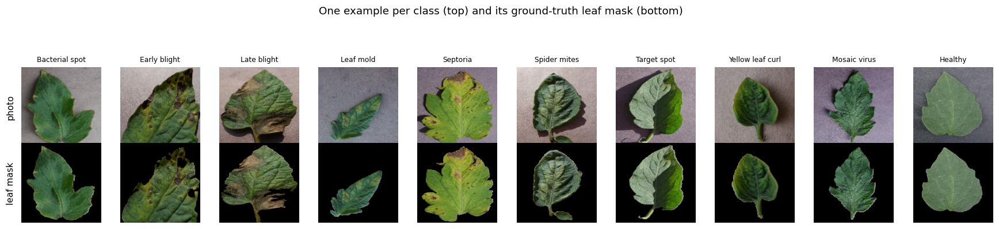

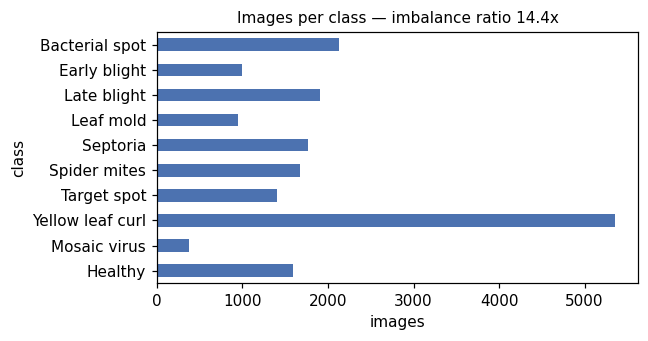

In [6]:
fig, axes = plt.subplots(2, N_CLASSES, figsize=(N_CLASSES * 1.6, 3.6))
for c in range(N_CLASSES):
    i = np.where(meta.label.values == c)[0][0]
    axes[0, c].imshow(IMAGES[i]); axes[0, c].set_title(SHORT[c], fontsize=8)
    axes[1, c].imshow(IMAGES[i] * MASKS[i][..., None])
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].text(-30, 80, "photo", rotation=90, va="center"); axes[1, 0].text(-30, 80, "leaf mask", rotation=90, va="center")
finish_figure("One example per class (top) and its ground-truth leaf mask (bottom)")

counts = meta["class"].value_counts().loc[SHORT]
ax = counts.plot.barh(figsize=(6, 3.2), color="#4C72B0"); ax.invert_yaxis()
ax.set_title(f"Images per class — imbalance ratio {counts.max() / counts.min():.1f}x"); ax.set_xlabel("images")
plt.tight_layout(); plt.show()

### 1.5 Data audit: is the background a label leak?
Before training anything we ask a simple question: **can you guess the label from *where* the photo was taken?**
We cross-tabulate the capture-session code (from the file names) against the class.

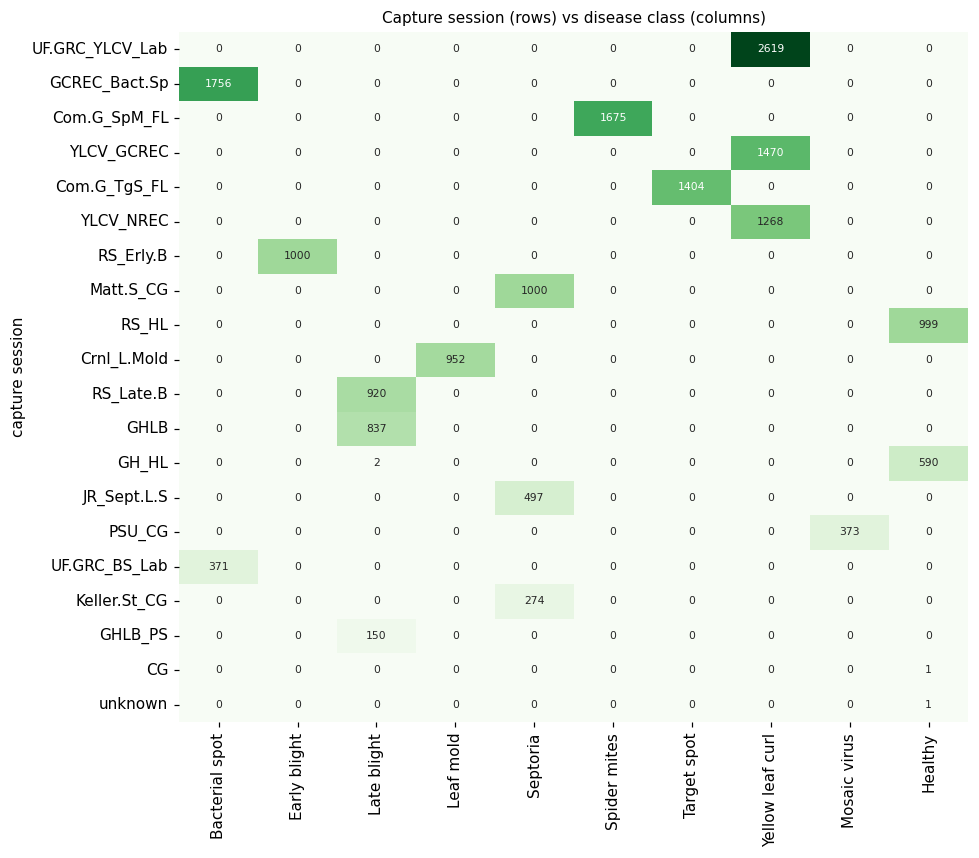

20 capture sessions; 20 of them contain a single class. Knowing only the session predicts the class for 100.0% of images.


In [7]:
ct = pd.crosstab(meta.session, meta["class"])[SHORT]
ct = ct.loc[ct.max(axis=1).sort_values(ascending=False).index]
purity = (ct.max(axis=1) / ct.sum(axis=1))
plt.figure(figsize=(9, 0.32 * len(ct) + 1.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Greens", cbar=False, annot_kws={"fontsize": 7})
plt.title("Capture session (rows) vs disease class (columns)"); plt.ylabel("capture session"); plt.xlabel("")
plt.tight_layout(); plt.show()
weighted_purity = (ct.max(axis=1).sum() / ct.values.sum())
print(f"{len(ct)} capture sessions; {(purity > 0.99).sum()} of them contain a single class. "
      f"Knowing only the session predicts the class for {weighted_purity:.1%} of images.")

**Why this matters.** Each capture session has its own table surface, lighting and camera settings. If the session
almost determines the class, then **the background carries the label**, and a CNN — which minimises training loss by
whatever signal is easiest — may learn "grey felt + harsh shadow = Early blight" instead of the lesions. This is a
*hypothesis* at this point; Section 4 tests whether our model actually does this.

## 2. Baseline CNN (trained from scratch)

**Architecture.** Five convolutional blocks (each: `Conv3×3 → BatchNorm → ReLU → Conv3×3 → BatchNorm → ReLU`), with
`MaxPool 2×2` between blocks: 160 → 80 → 40 → 20 → 10 pixels while channels grow 32 → 64 → 128 → 256 → 256.
Then **Global Average Pooling** (one number per feature map), dropout, and a linear layer to 10 classes.

Design choices:
* **Two stacked 3×3 convs** see a 5×5 region with fewer parameters and an extra non-linearity (VGG idea).
* **BatchNorm** stabilises and speeds up training; **GAP** instead of big fully-connected layers keeps the model small
  (~2.4 M parameters) and less prone to overfitting.
* The last block stays at **10×10** resolution — this is the layer Grad-CAM will explain, so we keep it from being too coarse.
* Input normalisation is **inside** the model, so inference code can pass plain 0–1 images.

**Training.** AdamW, one-cycle learning-rate schedule, label smoothing 0.05, mixed precision on GPU, early stopping on
validation **macro-F1** (treats all 10 classes equally, unlike accuracy which is dominated by the large classes).
Standard augmentation (on GPU): random flips, rotation ±25°, scale ±12%, shift ±8%, brightness/contrast/saturation ±20%.
No hue shift: colour is a real disease cue (yellowing, browning).

In [8]:
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.as_tensor(mean, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.as_tensor(std, dtype=torch.float32).view(1, 3, 1, 1))

    def forward(self, x):
        return (x - self.mean) / self.std


def conv_block(c_in: int, c_out: int) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )


class TomatoCNN(nn.Module):
    """Plain VGG-style CNN with global average pooling. Expects RGB images scaled to [0, 1]."""

    def __init__(self, mean, std, n_classes=N_CLASSES, widths=(32, 64, 128, 256, 256), dropout=0.3):
        super().__init__()
        self.normalize = Normalize(mean, std)
        layers, c_in = [], 3
        for i, w in enumerate(widths):
            layers.append(conv_block(c_in, w))
            if i < len(widths) - 1:
                layers.append(nn.MaxPool2d(2))
            c_in = w
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(c_in, n_classes)

    @property
    def gradcam_layer(self) -> nn.Module:
        return self.features[-1]          # last conv block (10x10 feature maps for 160px input)

    def forward(self, x):
        x = self.features(self.normalize(x))
        return self.classifier(self.dropout(self.pool(x).flatten(1)))


def channel_stats(X: torch.Tensor, chunk: int = 1024):
    """Per-channel mean/std of a uint8 image tensor, computed in chunks to save RAM."""
    s = sq = torch.zeros(3, dtype=torch.float64); n = 0
    for i in range(0, len(X), chunk):
        x = X[i:i + chunk].double() / 255
        s = s + x.sum(dim=(0, 2, 3)); sq = sq + (x ** 2).sum(dim=(0, 2, 3)); n += x.numel() // 3
    mean = s / n
    return mean.tolist(), (sq / n - mean ** 2).sqrt().tolist()


CH_MEAN, CH_STD = channel_stats(X_TR)
_m = TomatoCNN(CH_MEAN, CH_STD)
print(f"channel mean {np.round(CH_MEAN, 3)}, std {np.round(CH_STD, 3)}")
print(f"TomatoCNN parameters: {sum(p.numel() for p in _m.parameters()):,}")
with torch.no_grad():
    x = torch.zeros(1, 3, CFG.img_size, CFG.img_size)
    for i, layer in enumerate(_m.features):
        x = layer(x)
        if isinstance(layer, nn.Sequential):
            print(f"  block {i // 2 + 1}: output {tuple(x.shape[1:])}")
del _m

channel mean [0.45  0.465 0.4  ], std [0.177 0.155 0.193]
TomatoCNN parameters: 2,356,458
  block 1: output (32, 160, 160)
  block 2: output (64, 80, 80)
  block 3: output (128, 40, 40)
  block 4: output (256, 20, 20)
  block 5: output (256, 10, 10)


### 2.1 GPU augmentation and the training loop
`augment()` is shared by both models. The only extra argument, `background_swap`, is used by the **fixed** model in
Section 5 — keeping everything else identical is what makes the before/after comparison a controlled experiment.

In [9]:
def random_backgrounds(n: int, size: int, device) -> torch.Tensor:
    """Synthetic backgrounds: solid colour, colour gradient, smooth blobs, grey texture, or coloured noise."""
    H = W = size
    c1, c2 = torch.rand(n, 3, 1, 1, device=device), torch.rand(n, 3, 1, 1, device=device)
    ramp_x = torch.linspace(0, 1, W, device=device).view(1, 1, 1, W).expand(n, 1, H, W)
    ramp_y = torch.linspace(0, 1, H, device=device).view(1, 1, H, 1).expand(n, 1, H, W)
    ramp = torch.where(torch.rand(n, 1, 1, 1, device=device) < 0.5, ramp_x, ramp_y)
    smooth = lambda c, s: F.interpolate(torch.rand(n, c, s, s, device=device), size=(H, W), mode="bilinear", align_corners=False)
    candidates = torch.stack([
        c1.expand(n, 3, H, W),                                                    # solid colour
        c1 + (c2 - c1) * ramp,                                                    # gradient
        smooth(3, 6),                                                             # smooth colour blobs
        (0.6 * smooth(1, 24) + 0.4 * torch.rand(n, 1, H, W, device=device)).expand(n, 3, H, W) * (0.4 + c1.mean(1, keepdim=True)),
        (c1 + 0.2 * torch.randn(n, 3, H, W, device=device)),                      # coloured noise
    ], dim=1).clamp(0, 1)
    kind = torch.randint(0, candidates.shape[1], (n,), device=device)
    return candidates[torch.arange(n, device=device), kind]


def composite(x: torch.Tensor, mask: torch.Tensor, background: torch.Tensor) -> torch.Tensor:
    """Paste the leaf (mask, softened by 1px to avoid a hard cut-out edge) onto a new background."""
    soft = F.avg_pool2d(mask, 3, stride=1, padding=1)
    return soft * x + (1 - soft) * background


def augment(x: torch.Tensor, mask: torch.Tensor, background_swap: bool = False, p_swap: float = 0.8) -> torch.Tensor:
    """x: float images in [0,1] (N,3,H,W) on GPU; mask: (N,1,H,W) leaf masks."""
    n, dev = x.shape[0], x.device
    if background_swap:
        swap = (torch.rand(n, 1, 1, 1, device=dev) < p_swap).float()
        x = swap * composite(x, mask, random_backgrounds(n, x.shape[-1], dev)) + (1 - swap) * x
    # geometric: flips + random rotation / scale / shift (one affine warp)
    x = torch.where(torch.rand(n, 1, 1, 1, device=dev) < 0.5, x.flip(-1), x)
    x = torch.where(torch.rand(n, 1, 1, 1, device=dev) < 0.5, x.flip(-2), x)
    ang = (torch.rand(n, device=dev) * 2 - 1) * math.radians(25)
    scale = 1 + (torch.rand(n, device=dev) * 2 - 1) * 0.12
    tx, ty = (torch.rand(2, n, device=dev) * 2 - 1) * 0.08
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    # photometric: brightness, contrast, saturation (no hue: colour is a disease cue)
    jitter = lambda: 1 + (torch.rand(n, 1, 1, 1, device=dev) * 2 - 1) * 0.2
    x = x * jitter()
    mean = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - mean) * jitter() + mean
    gray = x.mean(dim=1, keepdim=True); x = (x - gray) * jitter() + gray
    return x.clamp(0, 1)


@torch.no_grad()
def predict_logits(model: nn.Module, X: torch.Tensor, batch_size: int = 256) -> torch.Tensor:
    """Logits for a uint8 image tensor (N,3,H,W). Runs on DEVICE, returns CPU float tensor."""
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        xb = X[i:i + batch_size].to(DEVICE, non_blocking=True).float() / 255
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            out.append(model(xb).float().cpu())
    return torch.cat(out)


def classification_metrics(y_true, y_pred) -> dict:
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro")}


def train_model(name: str, seed: int, background_swap: bool = False):
    """Train a TomatoCNN; keep the weights with the best validation macro-F1 (early stopping)."""
    set_seed(seed)
    model = TomatoCNN(CH_MEAN, CH_STD, dropout=CFG.dropout).to(DEVICE)
    steps_per_epoch = math.ceil(len(Y_TR) / CFG.batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG.lr, total_steps=CFG.epochs * steps_per_epoch, pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=CFG.label_smoothing)
    gen = torch.Generator().manual_seed(seed)

    best_f1, best_state, wait, history = -1.0, None, 0, []
    for epoch in range(1, CFG.epochs + 1):
        model.train(); t0 = time.time(); run_loss = run_correct = 0.0
        for idx in torch.randperm(len(Y_TR), generator=gen).split(CFG.batch_size):
            xb = X_TR[idx].to(DEVICE, non_blocking=True).float() / 255
            mb = M_TR[idx].to(DEVICE, non_blocking=True).float()
            yb = Y_TR[idx].to(DEVICE, non_blocking=True)
            xb = augment(xb, mb, background_swap=background_swap, p_swap=CFG.p_background_swap)
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                logits = model(xb); loss = loss_fn(logits, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(idx); run_correct += (logits.argmax(1) == yb).sum().item()

        val_pred = predict_logits(model, X_VA).argmax(1)
        val = classification_metrics(Y_VA, val_pred)
        history.append({"epoch": epoch, "train_loss": run_loss / len(Y_TR), "train_acc": run_correct / len(Y_TR),
                        "val_acc": val["accuracy"], "val_macro_f1": val["macro_f1"]})
        print(f"[{name} seed={seed}] epoch {epoch:2d} | loss {history[-1]['train_loss']:.3f} "
              f"| train acc {history[-1]['train_acc']:.3f} | val acc {val['accuracy']:.4f} "
              f"| val F1 {val['macro_f1']:.4f} | {time.time() - t0:.0f}s")
        if val["macro_f1"] > best_f1:
            best_f1, best_state, wait = val["macro_f1"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= CFG.patience:
                print(f"early stop: no val improvement for {CFG.patience} epochs"); break
    model.load_state_dict(best_state); model.eval()
    torch.save(best_state, CFG.artifacts / f"{name}_seed{seed}.pt")
    return model, pd.DataFrame(history)

### 2.2 Train the baseline (2 seeds)
Training each experiment with two random seeds shows how much of any difference is just run-to-run noise.

[baseline seed=0] epoch  1 | loss 1.139 | train acc 0.681 | val acc 0.6520 | val F1 0.6080 | 24s
[baseline seed=0] epoch  2 | loss 0.828 | train acc 0.792 | val acc 0.6513 | val F1 0.5039 | 21s
[baseline seed=0] epoch  3 | loss 0.730 | train acc 0.834 | val acc 0.8102 | val F1 0.7541 | 22s
[baseline seed=0] epoch  4 | loss 0.648 | train acc 0.867 | val acc 0.5874 | val F1 0.5833 | 23s
[baseline seed=0] epoch  5 | loss 0.575 | train acc 0.897 | val acc 0.8406 | val F1 0.7902 | 24s
[baseline seed=0] epoch  6 | loss 0.514 | train acc 0.923 | val acc 0.8868 | val F1 0.8557 | 24s
[baseline seed=0] epoch  7 | loss 0.489 | train acc 0.936 | val acc 0.8891 | val F1 0.8687 | 23s
[baseline seed=0] epoch  8 | loss 0.464 | train acc 0.943 | val acc 0.9681 | val F1 0.9597 | 23s
[baseline seed=0] epoch  9 | loss 0.441 | train acc 0.953 | val acc 0.9496 | val F1 0.9330 | 24s
[baseline seed=0] epoch 10 | loss 0.426 | train acc 0.958 | val acc 0.9661 | val F1 0.9498 | 24s
[baseline seed=0] epoch 11 | l

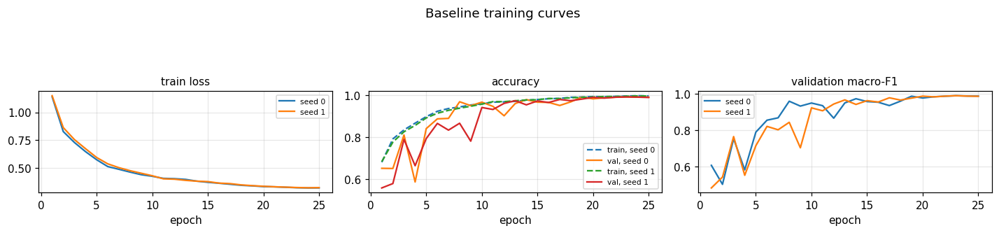

In [10]:
baseline_models, baseline_hist = {}, {}
for seed in CFG.seeds:
    baseline_models[seed], baseline_hist[seed] = train_model("baseline", seed, background_swap=False)
baseline = baseline_models[CFG.seeds[0]]          # the model we diagnose in depth
mem_report("baseline trained")


def plot_history(hists: dict, title: str):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    for seed, h in hists.items():
        axes[0].plot(h.epoch, h.train_loss, label=f"seed {seed}")
        axes[1].plot(h.epoch, h.train_acc, "--", label=f"train, seed {seed}"); axes[1].plot(h.epoch, h.val_acc, label=f"val, seed {seed}")
        axes[2].plot(h.epoch, h.val_macro_f1, label=f"seed {seed}")
    for ax, t in zip(axes, ["train loss", "accuracy", "validation macro-F1"]):
        ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    finish_figure(title)


plot_history(baseline_hist, "Baseline training curves")

### 2.3 Baseline results on the held-out test set

seed 0: test accuracy 0.9896 | macro-F1 0.9880
seed 1: test accuracy 0.9911 | macro-F1 0.9907


,precision,recall,f1-score,support
Bacterial spot,0.9869,0.9934,0.9902,304.0000
Early blight,1.0000,0.9931,0.9965,144.0000
Late blight,1.0000,0.9809,0.9904,262.0000
Leaf mold,1.0000,0.9928,0.9964,138.0000
Septoria,0.9960,1.0000,0.9980,252.0000
Spider mites,0.9637,1.0000,0.9815,239.0000
Target spot,0.9947,0.9350,0.9639,200.0000
Yellow leaf curl,0.9974,0.9961,0.9967,766.0000
Mosaic virus,1.0000,0.9804,0.9901,51.0000
Healthy,0.9583,0.9957,0.9766,231.0000


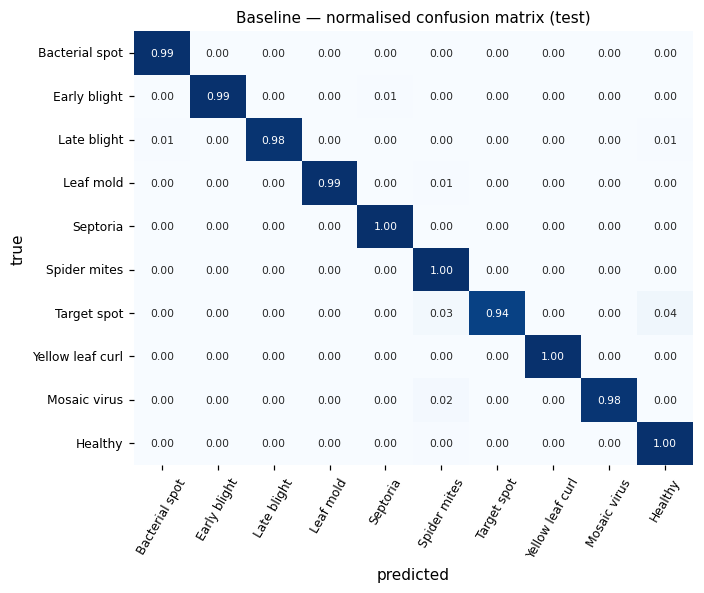

In [11]:
def evaluate_split(model, X, y) -> dict:
    logits = predict_logits(model, X)
    pred = logits.argmax(1).numpy()
    return {**classification_metrics(y.numpy(), pred), "pred": pred, "logits": logits}


def per_class_report(y_true, y_pred) -> pd.DataFrame:
    rep = classification_report(y_true, y_pred, labels=range(N_CLASSES), target_names=SHORT, output_dict=True, zero_division=0)
    return pd.DataFrame(rep).T.loc[SHORT + ["macro avg"], ["precision", "recall", "f1-score", "support"]]


def plot_confusion(y_true, y_pred, title: str, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES), normalize="true")
    ax = ax or plt.subplots(figsize=(6.5, 5.5))[1]
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=SHORT, yticklabels=SHORT, vmin=0, vmax=1,
                cbar=False, ax=ax, annot_kws={"fontsize": 7})
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    ax.tick_params(axis="x", rotation=60, labelsize=8); ax.tick_params(axis="y", labelsize=8)
    return ax


base_test = {s: evaluate_split(m, X_TE, Y_TE) for s, m in baseline_models.items()}
for s, r in base_test.items():
    print(f"seed {s}: test accuracy {r['accuracy']:.4f} | macro-F1 {r['macro_f1']:.4f}")
B0 = base_test[CFG.seeds[0]]
display(per_class_report(Y_TE.numpy(), B0["pred"]).style.format(precision=4).set_caption("Baseline (seed 0) — per-class test metrics"))
plot_confusion(Y_TE.numpy(), B0["pred"], "Baseline — normalised confusion matrix (test)"); plt.tight_layout(); plt.show()

On a random split of PlantVillage, accuracy in the high 90s is normal. **A high test score does not tell us *why*
the model is right.** The test set comes from the same sessions (same tables, same lighting) as the training set, so a
background shortcut would be rewarded by the test set too. This is exactly the blind spot Grad-CAM is for.

## 3. Grad-CAM, implemented from scratch

For a class $c$ with score (logit) $y^c$ and the last conv layer's feature maps $A^k$ (here 256 maps of 10×10):

1. **Gradients**: $\dfrac{\partial y^c}{\partial A^k_{ij}}$ — how much the class score would change if this activation increased.
2. **Channel weights** (global-average-pooled gradients): $\alpha_k^c = \dfrac{1}{Z}\sum_{i,j}\dfrac{\partial y^c}{\partial A^k_{ij}}$ — how important feature map $k$ is for class $c$.
3. **Map**: $L^c_{\text{Grad-CAM}} = \mathrm{ReLU}\big(\sum_k \alpha_k^c A^k\big)$ — keep only regions that push *towards* class $c$.
4. Upsample 10×10 → 160×160 and overlay on the image.

We use the **last** conv block because it has the most class-specific, high-level features while still keeping a
spatial layout. The implementation uses a forward hook (stores $A$) and a tensor hook (stores $\partial y^c/\partial A$),
and works on whole batches, so we can compute Grad-CAM for the *entire* test set and measure things, not just look at
a few pictures.

In [12]:
class GradCAM:
    """Batched Grad-CAM. cams are returned upsampled to the input size and scaled to [0, 1] per image."""

    def __init__(self, model: nn.Module, layer: nn.Module):
        self.model, self.activations, self.gradients = model, None, None
        self._handle = layer.register_forward_hook(self._save)

    def _save(self, module, inputs, output):
        self.activations = output
        if output.requires_grad:
            output.register_hook(lambda g: setattr(self, "gradients", g))

    def __call__(self, x: torch.Tensor, target: torch.Tensor | None = None):
        """x: float (N,3,H,W) in [0,1] on DEVICE. target: class per image (default = predicted class)."""
        self.model.eval()
        with torch.enable_grad():
            logits = self.model(x)
            target = logits.argmax(1) if target is None else target.to(x.device)
            self.model.zero_grad(set_to_none=True)
            logits.gather(1, target[:, None]).sum().backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)                  # alpha_k^c
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))       # ReLU(sum_k alpha_k A^k)
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.detach(), logits.detach(), target

    def remove(self):
        self._handle.remove()


def compute_cams(model, X: torch.Tensor, targets=None, batch_size: int = 64):
    """Grad-CAM for a whole uint8 image tensor. Returns cams (N,H,W float16, CPU) and logits."""
    cam_fn, cams, logits = GradCAM(model, model.gradcam_layer), [], []
    for i in range(0, len(X), batch_size):
        xb = X[i:i + batch_size].to(DEVICE).float() / 255
        tb = None if targets is None else torch.as_tensor(targets[i:i + batch_size])
        c, l, _ = cam_fn(xb, tb)
        cams.append(c.half().cpu()); logits.append(l.float().cpu())
    cam_fn.remove()
    return torch.cat(cams), torch.cat(logits)


def overlay(img_u8: np.ndarray, cam: np.ndarray, alpha: float = 0.45, mask: np.ndarray | None = None) -> np.ndarray:
    """Jet heatmap over the image; optional white contour of the leaf mask."""
    heat = cv2.applyColorMap(np.uint8(255 * np.clip(cam, 0, 1)), cv2.COLORMAP_JET)[..., ::-1]
    out = np.uint8((1 - alpha) * img_u8 + alpha * heat)
    if mask is not None:
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(out, contours, -1, (255, 255, 255), 1)
    return out


def u8(x_chw: torch.Tensor) -> np.ndarray:
    return x_chw.permute(1, 2, 0).numpy()

### 3.1 Sanity check: is our Grad-CAM actually explaining the model?
Adebayo et al. (2018, *Sanity Checks for Saliency Maps*) showed that some saliency methods produce nice-looking maps
even for a network with **random weights** — i.e. they are edge detectors, not explanations. We repeat their
**model-randomisation test**: if Grad-CAM is faithful, the maps from the trained model and from a randomly
re-initialised copy should be *unrelated* (low rank correlation). We also check that it is **class-discriminative**:
maps for the predicted class vs. the 2nd most likely class should differ.

Spearman rank correlation, trained vs RANDOM-weights model : +0.088 (should be ~0)
Spearman rank correlation, top-1 class vs 2nd class map    : -0.011 (should be clearly < 1)


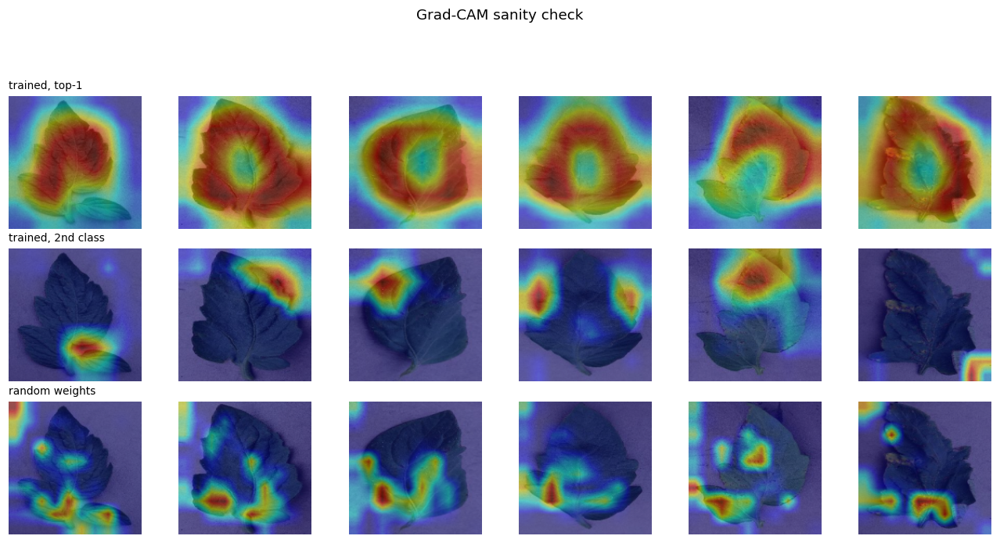

In [13]:
n_check = min(64, len(X_TE))
cams_trained, logits_chk = compute_cams(baseline, X_TE[:n_check])
random_model = copy.deepcopy(baseline)
for m in random_model.modules():
    if hasattr(m, "reset_parameters") and not isinstance(m, Normalize):
        m.reset_parameters()
cams_random, _ = compute_cams(random_model, X_TE[:n_check])
second_class = logits_chk.argsort(dim=1, descending=True)[:, 1]
cams_second, _ = compute_cams(baseline, X_TE[:n_check], targets=second_class)

def rank_corr(a, b):
    small = lambda c: F.avg_pool2d(c.float()[:, None], 8).flatten(1).numpy()    # compare at 20x20
    return np.array([spearmanr(u, v)[0] for u, v in zip(small(a), small(b))])

rc_random = np.nan_to_num(rank_corr(cams_trained, cams_random))
rc_second = np.nan_to_num(rank_corr(cams_trained, cams_second))
print(f"Spearman rank correlation, trained vs RANDOM-weights model : {rc_random.mean():+.3f} (should be ~0)")
print(f"Spearman rank correlation, top-1 class vs 2nd class map    : {rc_second.mean():+.3f} (should be clearly < 1)")

fig, axes = plt.subplots(3, 6, figsize=(12, 6.3))
for j in range(6):
    img = u8(X_TE[j])
    for row, (c, name) in enumerate([(cams_trained, "trained, top-1"), (cams_second, "trained, 2nd class"), (cams_random, "random weights")]):
        axes[row, j].imshow(overlay(img, c[j].float().numpy())); axes[row, j].axis("off")
        if j == 0: axes[row, j].set_title(name, loc="left", fontsize=9)
finish_figure("Grad-CAM sanity check")
del random_model

## 4. Diagnosis — what is the baseline actually looking at?

We go from *looking* (4.1) to *measuring* (4.2) to *intervening* (4.3) — a pattern counts as a real, repeatable
failure only if it shows up in all three.

### 4.1 Look: Grad-CAM on test images
White line = true leaf boundary (from the segmented twin). Warm colours = regions that drove the predicted class.

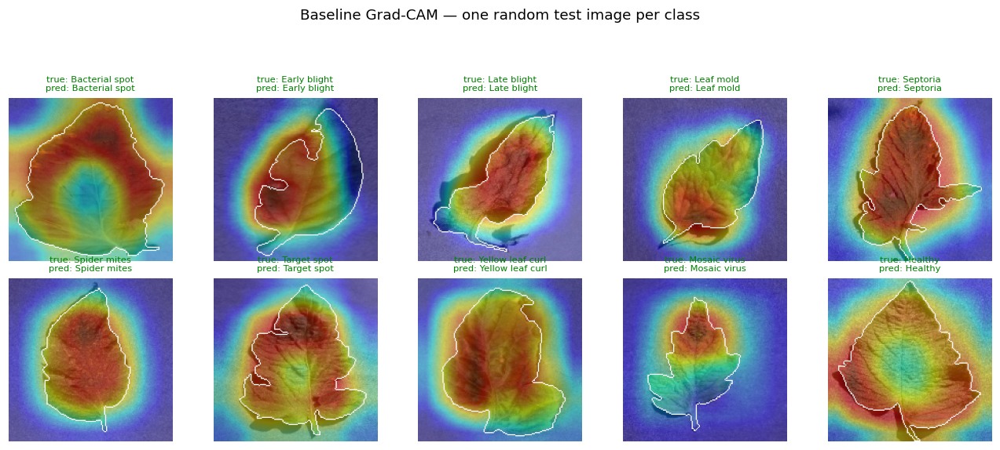

In [14]:
CAMS_B, LOGITS_B = compute_cams(baseline, X_TE)
PRED_B = LOGITS_B.argmax(1).numpy()


def cam_grid(indices, X, M, cams, preds, y, title, ncols=5, extra=None):
    nrows = math.ceil(len(indices) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.4, nrows * 2.6))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).flat, indices):
        ax.imshow(overlay(u8(X[i]), cams[i].float().numpy(), mask=M[i, 0].numpy()))
        ok = preds[i] == y[i]
        txt = f"true: {SHORT[y[i]]}\npred: {SHORT[preds[i]]}" + (f"\n{extra[i]}" if extra is not None else "")
        ax.set_title(txt, fontsize=7.5, color="green" if ok else "red")
    finish_figure(title)


y_te = Y_TE.numpy()
rng = np.random.default_rng(0)
one_per_class = [rng.choice(np.where(y_te == c)[0]) for c in range(N_CLASSES)]
cam_grid(one_per_class, X_TE, M_TE, CAMS_B, PRED_B, y_te, "Baseline Grad-CAM — one random test image per class")

### 4.2 Measure: where does the Grad-CAM energy go?
For every test image we split the image into three zones using the true leaf mask — **leaf interior**, a thin
**leaf boundary** band (±4 px), and **background** — and compute the share of Grad-CAM energy in each.
Comparing a zone's energy share with its area share gives an **attention lift**: >1 means the model looks there
*more than chance*. A model that "reads the leaf" should put most energy on the interior (where lesions are).

,mean energy share,mean area share,attention lift
zone,,,
interior,0.416,0.293,1.420
boundary,0.242,0.188,1.288
background,0.341,0.519,0.658


Images whose Grad-CAM peak lies OFF the leaf: 12.1%
Images with >30% of energy on background:    67.8%


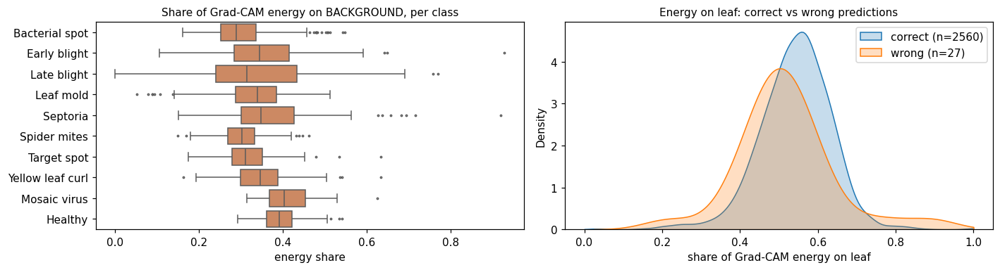

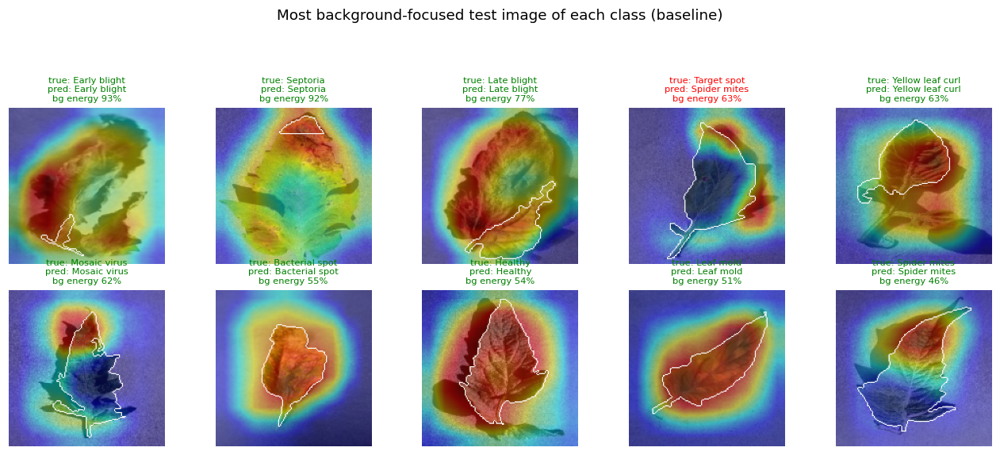

In [15]:
def zone_masks(M: torch.Tensor, band: int = 9):
    """Leaf interior / boundary band / background masks from (N,1,H,W) leaf masks."""
    m = M.float()
    dil = F.max_pool2d(m, band, stride=1, padding=band // 2)
    ero = 1 - F.max_pool2d(1 - m, band, stride=1, padding=band // 2)
    return {"interior": ero[:, 0], "boundary": (dil - ero)[:, 0], "background": (1 - dil)[:, 0]}


def _cam_energy_chunk(cams: torch.Tensor, M: torch.Tensor) -> pd.DataFrame:
    zones, c = zone_masks(M), cams.float()
    total = c.sum(dim=(1, 2)) + 1e-8
    out = {}
    for z, zm in zones.items():
        out[f"energy_{z}"] = ((c * zm).sum(dim=(1, 2)) / total).numpy()
        out[f"area_{z}"] = zm.mean(dim=(1, 2)).numpy()
    out["leaf_ratio"] = ((c * M[:, 0].float()).sum(dim=(1, 2)) / total).numpy()   # energy on leaf (interior+edge)
    peak = c.flatten(1).argmax(1)                                                  # "pointing game": peak on leaf?
    out["peak_on_leaf"] = M[:, 0].reshape(len(M), -1).gather(1, peak[:, None].long())[:, 0].numpy().astype(bool)
    return pd.DataFrame(out)


def cam_energy(cams: torch.Tensor, M: torch.Tensor, chunk: int = 256) -> pd.DataFrame:
    """Per-image share of Grad-CAM energy per zone (computed in chunks to keep RAM low)."""
    return pd.concat([_cam_energy_chunk(cams[i:i + chunk], M[i:i + chunk]) for i in range(0, len(cams), chunk)],
                     ignore_index=True)


def summarize_energy(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for z in ["interior", "boundary", "background"]:
        e, a = df[f"energy_{z}"].mean(), df[f"area_{z}"].mean()
        rows.append({"zone": z, "mean energy share": e, "mean area share": a, "attention lift": e / a})
    return pd.DataFrame(rows).set_index("zone")


EN_B = cam_energy(CAMS_B, M_TE)
EN_B["correct"] = PRED_B == y_te
EN_B["class"] = [SHORT[c] for c in y_te]
display(summarize_energy(EN_B).style.format(precision=3).set_caption("Baseline — where Grad-CAM energy goes (test set)"))
print(f"Images whose Grad-CAM peak lies OFF the leaf: {(~EN_B.peak_on_leaf).mean():.1%}")
print(f"Images with >30% of energy on background:    {(EN_B.energy_background > 0.30).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
sns.boxplot(data=EN_B, y="class", x="energy_background", order=SHORT, ax=axes[0], color="#DD8452", fliersize=1.5)
axes[0].set_title("Share of Grad-CAM energy on BACKGROUND, per class"); axes[0].set_xlabel("energy share"); axes[0].set_ylabel("")
for ok, lab in [(True, "correct"), (False, "wrong")]:
    if (EN_B.correct == ok).sum() > 1:
        sns.kdeplot(EN_B.leaf_ratio[EN_B.correct == ok], ax=axes[1], label=f"{lab} (n={(EN_B.correct == ok).sum()})", fill=True, clip=(0, 1))
axes[1].set_title("Energy on leaf: correct vs wrong predictions"); axes[1].set_xlabel("share of Grad-CAM energy on leaf"); axes[1].legend()
plt.tight_layout(); plt.show()

worst = EN_B.sort_values("energy_background", ascending=False).groupby("class").head(1).index[:10].tolist()
cam_grid(worst, X_TE, M_TE, CAMS_B, PRED_B, y_te, "Most background-focused test image of each class (baseline)",
         extra=[f"bg energy {e:.0%}" for e in EN_B.energy_background])

### 4.3 Intervene: does the background actually *cause* the predictions?
Heatmaps show correlation, not causation. To test causation we **edit the images** and watch the predictions:

| Test | What we do | A model reading the leaf would… |
|---|---|---|
| **Background only** | remove the leaf (dilated mask, OpenCV inpainting) and keep only its background | score ≈ 10 % (chance) |
| **Cross-class background** | paste each leaf onto the inpainted background of a test image from a **different class** | keep its accuracy, and **not** follow the background's class |
| **Black background** | the dataset's own segmented version (leaf on black) | keep its accuracy |
| **Held-out textures** | leaf on real-world textures (grass / gravel / brick photos) | keep its accuracy |

*Cross-class backgrounds* and *held-out textures* are deliberately **never** used by the fix in Section 5 (which only
trains on synthetic backgrounds), so they give an honest test of the fix later.

stress sets built in 96s
[memory] test stress sets built: process 5.5 GB | system 6.4 / 13.6 GB


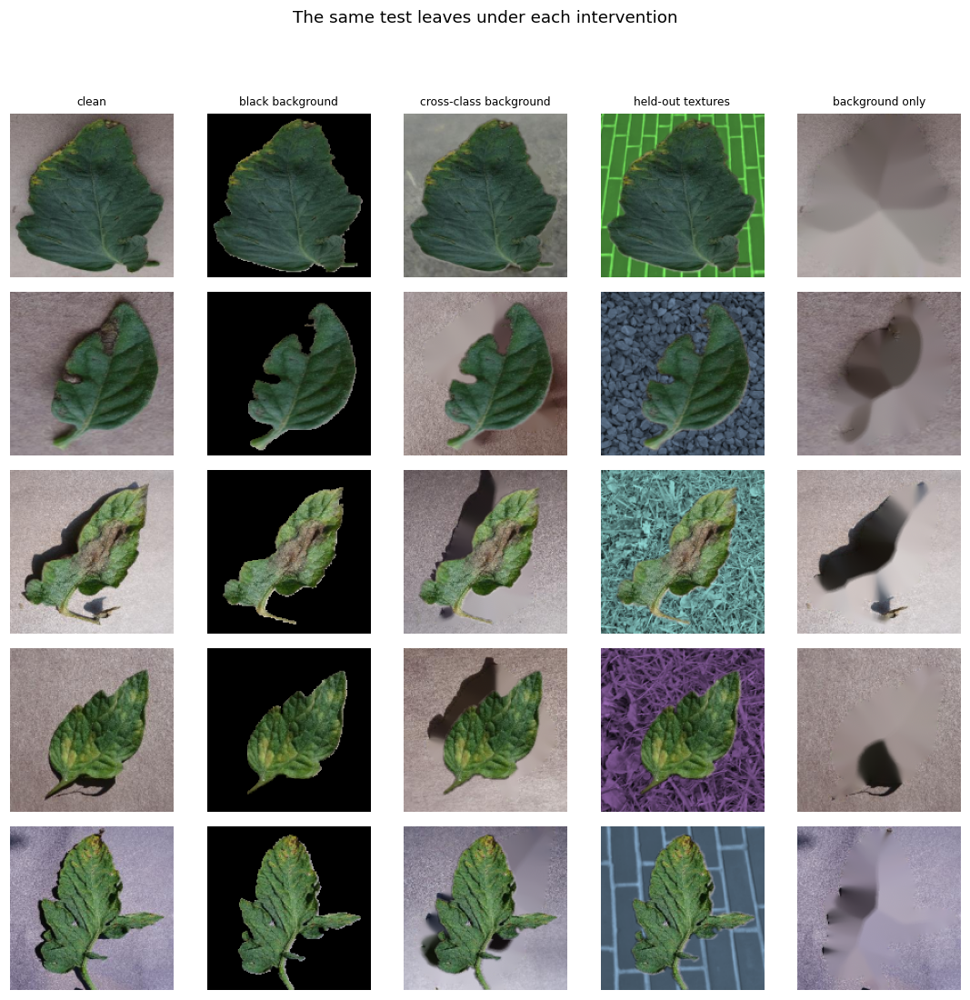

In [16]:
def background_plates(X: torch.Tensor, M: torch.Tensor) -> torch.Tensor:
    """Remove the leaf: inpaint a dilated leaf mask so only the photo's background remains."""
    kernel = np.ones((5, 5), np.uint8)
    def one(i):
        img, m = np.ascontiguousarray(u8(X[i])), cv2.dilate(M[i, 0].numpy(), kernel, iterations=2)
        return cv2.inpaint(img, m, 5, cv2.INPAINT_TELEA)
    with ThreadPoolExecutor(max_workers=8) as pool:
        plates = list(pool.map(one, range(len(X))))
    return torch.from_numpy(np.stack(plates)).permute(0, 3, 1, 2).contiguous()


def cross_class_partner(y: np.ndarray, seed: int = 0) -> np.ndarray:
    """For each image, a random image of a DIFFERENT class (its background will be borrowed)."""
    rng = np.random.default_rng(seed)
    return np.array([rng.choice(np.where(y != c)[0]) for c in y])


def paste(X: torch.Tensor, M: torch.Tensor, backgrounds: torch.Tensor, chunk: int = 256) -> torch.Tensor:
    """Leaves of X (via masks M) on new backgrounds; uint8 in/out, processed in chunks to keep RAM low."""
    out = torch.empty(X.shape, dtype=torch.uint8)
    for i in range(0, len(X), chunk):
        s = slice(i, i + chunk)
        x = composite(X[s].float() / 255, M[s].float(), backgrounds[s].float() / 255)
        out[s] = (x * 255).round().clamp(0, 255).to(torch.uint8)
    return out


def cross_class_set(X, M, y, seed=0, plates=None):
    """Each leaf pasted onto the (leaf-removed) background of a random image from a different class."""
    plates = background_plates(X, M) if plates is None else plates
    partner = cross_class_partner(y, seed)
    return paste(X, M, plates[torch.from_numpy(partner)]), partner


def texture_backgrounds(n: int, size: int, seed: int = 0) -> torch.Tensor:
    """Crops of real photographs of textures (scikit-image sample data), randomly tinted — never seen in training."""
    from skimage import data as skdata
    textures = [t if t.ndim == 2 else cv2.cvtColor(t, cv2.COLOR_RGB2GRAY) for t in (skdata.grass(), skdata.gravel(), skdata.brick())]
    rng = np.random.default_rng(seed)
    out = np.empty((n, size, size, 3), np.uint8)
    for i in range(n):
        t = textures[rng.integers(len(textures))]
        crop_size = rng.integers(size, min(t.shape) // 1)
        y0, x0 = rng.integers(0, t.shape[0] - crop_size + 1), rng.integers(0, t.shape[1] - crop_size + 1)
        g = cv2.resize(t[y0:y0 + crop_size, x0:x0 + crop_size], (size, size), interpolation=cv2.INTER_AREA).astype(np.float32) / 255
        tint = rng.uniform(0.35, 1.0, size=3)
        out[i] = np.uint8(255 * np.clip(g[..., None] * tint * 1.3, 0, 1))
    return torch.from_numpy(out).permute(0, 3, 1, 2).contiguous()


def build_stress_sets(X, M, y, seed=0):
    plates = background_plates(X, M)
    cross, partner = cross_class_set(X, M, y, seed, plates=plates)
    return {
        "clean": X,
        "black background": (X * M).contiguous(),
        "cross-class background": cross,
        "held-out textures": paste(X, M, texture_backgrounds(len(X), X.shape[-1], seed)),
        "background only": plates,
    }, partner


t0 = time.time()
STRESS_TE, PARTNER_TE = build_stress_sets(X_TE, M_TE, y_te, seed=0)
print(f"stress sets built in {time.time() - t0:.0f}s")
mem_report("test stress sets built")

j = one_per_class[:5]
fig, axes = plt.subplots(len(j), len(STRESS_TE), figsize=(len(STRESS_TE) * 2, len(j) * 2))
for r, i in enumerate(j):
    for c, (name, Xs) in enumerate(STRESS_TE.items()):
        axes[r, c].imshow(u8(Xs[i])); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(name, fontsize=8)
finish_figure("The same test leaves under each intervention")

,baseline
clean,99.0%
black background,21.0%
cross-class background,67.1%
held-out textures,26.8%
background only,40.0%
follows background class,11.8%


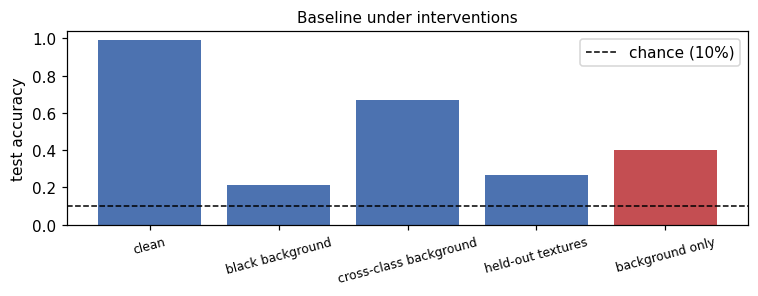

In [17]:
def stress_suite(model, stress: dict, y: np.ndarray, partner: np.ndarray) -> dict:
    """Accuracy under each intervention + how often the prediction follows the borrowed background's class."""
    res = {}
    for name, Xs in stress.items():
        pred = predict_logits(model, Xs).argmax(1).numpy()
        res[name] = accuracy_score(y, pred)
        if name == "cross-class background":
            res["follows background class"] = float((pred == y[partner]).mean())
            res["_pred_cross"] = pred
    return res


def stress_table(results: dict) -> pd.DataFrame:
    keys = ["clean", "black background", "cross-class background", "held-out textures", "background only", "follows background class"]
    return pd.DataFrame({name: {k: r[k] for k in keys} for name, r in results.items()})


ST_B = stress_suite(baseline, STRESS_TE, y_te, PARTNER_TE)
display(stress_table({"baseline": ST_B}).style.format("{:.1%}").set_caption(
    "Baseline accuracy under interventions (chance = 10%; 'follows background class' = predicted the class of the borrowed background)"))

conds = ["clean", "black background", "cross-class background", "held-out textures", "background only"]
plt.figure(figsize=(7, 2.8))
plt.bar(conds, [ST_B[c] for c in conds], color=["#4C72B0"] * 4 + ["#C44E52"])
plt.axhline(1 / N_CLASSES, ls="--", c="k", lw=1, label="chance (10%)")
plt.ylabel("test accuracy"); plt.xticks(rotation=15, fontsize=8); plt.legend(); plt.title("Baseline under interventions")
plt.tight_layout(); plt.show()

Grad-CAM **on the edited images** shows the mechanism: below, the same leaf on its own background vs. on another
class's background. If the heatmap moves to the background and the prediction changes, the background is
being used as evidence.

Correct on clean but wrong on cross-class background: 830 / 2587 test images; 299 of them switched to the class the background came from.


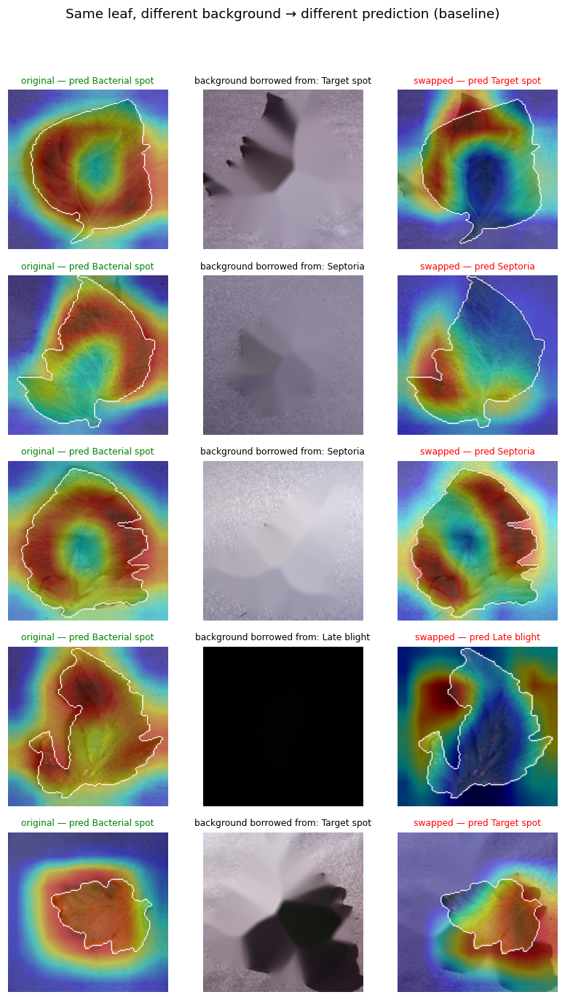

In [18]:
CAMS_B_CROSS, LOGITS_B_CROSS = compute_cams(baseline, STRESS_TE["cross-class background"])
pred_cross_b = LOGITS_B_CROSS.argmax(1).numpy()
flipped = np.where((PRED_B == y_te) & (pred_cross_b != y_te))[0]
followed = flipped[pred_cross_b[flipped] == y_te[PARTNER_TE[flipped]]]
show = (list(followed) + [i for i in flipped if i not in followed])[:5]
print(f"Correct on clean but wrong on cross-class background: {len(flipped)} / {len(y_te)} test images; "
      f"{len(followed)} of them switched to the class the background came from.")

if show:
    fig, axes = plt.subplots(len(show), 3, figsize=(7.5, 2.5 * len(show)), squeeze=False)
    for r, i in enumerate(show):
        axes[r, 0].imshow(overlay(u8(X_TE[i]), CAMS_B[i].float().numpy(), mask=M_TE[i, 0].numpy()))
        axes[r, 0].set_title(f"original — pred {SHORT[PRED_B[i]]}", fontsize=8, color="green")
        axes[r, 1].imshow(u8(STRESS_TE["background only"][PARTNER_TE[i]]))
        axes[r, 1].set_title(f"background borrowed from: {SHORT[y_te[PARTNER_TE[i]]]}", fontsize=8)
        axes[r, 2].imshow(overlay(u8(STRESS_TE["cross-class background"][i]), CAMS_B_CROSS[i].float().numpy(), mask=M_TE[i, 0].numpy()))
        axes[r, 2].set_title(f"swapped — pred {SHORT[pred_cross_b[i]]}", fontsize=8, color="red")
        for a in axes[r]: a.axis("off")
    finish_figure("Same leaf, different background → different prediction (baseline)")

### 4.4 Root cause in the data: the background alone predicts the label
Independently of any CNN: a simple **Random Forest on colour histograms of background pixels only** (leaf + margin
removed). If this classifier beats chance by a wide margin, the dataset itself contains the shortcut, which explains why
the CNN learned it.

In [19]:
def background_color_features(images: np.ndarray, masks: np.ndarray) -> np.ndarray:
    kernel = np.ones((9, 9), np.uint8)
    feats = []
    for img, m in zip(images, masks):
        bg = cv2.dilate(m, kernel, iterations=2) == 0
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[bg]
        if len(hsv) < 50:                                   # leaf fills the frame: no background to describe
            feats.append(np.zeros(3 * 16 + 6)); continue
        hists = [np.histogram(hsv[:, ch], bins=16, range=(0, 256))[0] / len(hsv) for ch in range(3)]
        feats.append(np.concatenate(hists + [hsv.mean(0) / 255, hsv.std(0) / 255]))
    return np.array(feats)


rf =RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0)
sl_tr, sl_te = split_slice("train"), split_slice("test")           # views, no copies
rf.fit(background_color_features(IMAGES[sl_tr], MASKS[sl_tr]), meta.label.values[sl_tr])
bg_only_pred = rf.predict(background_color_features(IMAGES[sl_te], MASKS[sl_te]))
print(f"Background-colour-only Random Forest: test accuracy {accuracy_score(y_te, bg_only_pred):.1%} "
      f"(chance 10%, always guessing the largest class {np.bincount(y_te).max() / len(y_te):.1%})")

Background-colour-only Random Forest: test accuracy 86.9% (chance 10%, always guessing the largest class 29.6%)


### 4.5 Secondary pattern: which classes get confused, and what does Grad-CAM show there?

Most frequent confusions (true → predicted):
       Target spot → Healthy          8 images
       Target spot → Spider mites     5 images
  Yellow leaf curl → Bacterial spot   2 images
       Late blight → Healthy          2 images
       Late blight → Bacterial spot   2 images


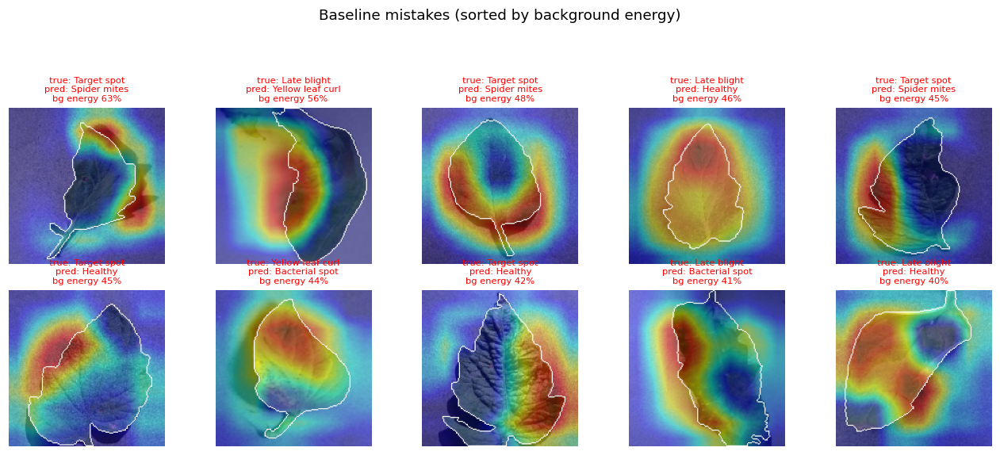

In [20]:
cm = confusion_matrix(y_te, PRED_B, labels=range(N_CLASSES))
np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], i, j) for i in range(N_CLASSES) for j in range(N_CLASSES) if cm[i, j] > 0), reverse=True)[:5]
print("Most frequent confusions (true → predicted):")
for n, i, j in pairs:
    print(f"  {SHORT[i]:>16s} → {SHORT[j]:<16s} {n} images")
wrong = np.where(PRED_B != y_te)[0]
if len(wrong):
    cam_grid(wrong[np.argsort(-EN_B.energy_background.values[wrong])][:10], X_TE, M_TE, CAMS_B, PRED_B, y_te,
             "Baseline mistakes (sorted by background energy)", extra=[f"bg energy {e:.0%}" for e in EN_B.energy_background])

### 4.6 Diagnosis summary
The cell below prints the evidence. The **failure pattern** we target is:

> **Background shortcut.** The baseline uses the photo's background (table surface, lighting, shadows — which in
> PlantVillage identify the capture session and therefore the class) as evidence for the disease. Grad-CAM puts a
> measurable share of its energy outside the leaf, removing the leaf leaves the model well above chance, and moving a
> leaf onto another class's background makes the prediction drop and often **follow the background's class**.

It is *repeatable*: it is measured over the whole test set, present in every class, and reproduced by a second seed (Section 6).

In [21]:
def diagnosis_summary(name, energy: pd.DataFrame, st: dict) -> pd.Series:
    return pd.Series({
        "clean test accuracy": st["clean"],
        "Grad-CAM energy on background": energy.energy_background.mean(),
        "Grad-CAM energy on leaf boundary": energy.energy_boundary.mean(),
        "Grad-CAM peak off the leaf": (~energy.peak_on_leaf).mean(),
        "accuracy, background only (chance 10%)": st["background only"],
        "accuracy, leaf on another class's background": st["cross-class background"],
        "→ prediction follows the background's class": st["follows background class"],
        "accuracy, held-out textures": st["held-out textures"],
    }, name=name)


display(diagnosis_summary("baseline", EN_B, ST_B).to_frame().style.format("{:.1%}"))

,baseline
clean test accuracy,99.0%
Grad-CAM energy on background,34.1%
Grad-CAM energy on leaf boundary,24.2%
Grad-CAM peak off the leaf,12.1%
"accuracy, background only (chance 10%)",40.0%
"accuracy, leaf on another class's background",67.1%
→ prediction follows the background's class,11.8%
"accuracy, held-out textures",26.8%


## 5. Targeted fix: mask-guided background randomization

**Diagnosis → fix.** The model uses the background because, in the training data, the background *predicts the label*.
The targeted fix is to **break that correlation at its source**: during training, with probability 0.8, we cut the leaf
out with its mask and paste it onto a **random synthetic background** (solid colours, gradients, smooth blobs, grey
textures, coloured noise). The leaf and its label stay the same; the background becomes pure noise. A background
feature is then useless for lowering the loss, so gradient descent stops relying on it and must use the leaf.

**Why this fix, not another one?**
* *More generic augmentation / bigger model / longer training* — none of them changes the fact that the background
  predicts the label; the shortcut would still be rewarded.
* *Cropping to the leaf* — still leaves background pixels around the leaf, and the leaf shape/size per session remains.
* *Training on the black-background (segmented) images only* — makes the model depend on a perfect segmentation at
  inference time, which real photos do not have.
* *Attention-supervision loss* ("Right for the Right Reasons", penalising Grad-CAM outside the mask) — treats the
  symptom (the heatmap) instead of the cause (the data); it is a sensible next step but more complex to tune.

**Controlled experiment.** Same architecture, data split, hyper-parameters, epochs, seeds and all other augmentation —
the **only** change is `background_swap=True`. And we evaluate on backgrounds the fix **never** saw in training
(real backgrounds from other classes, real texture photos).

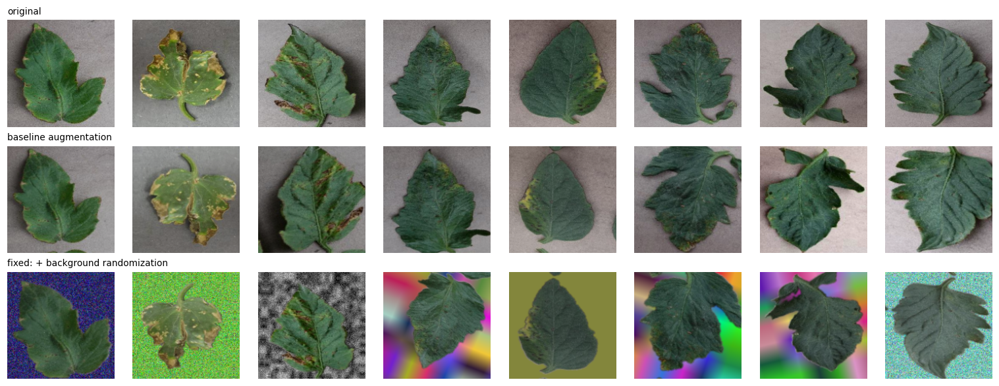

In [22]:
xb = X_TR[:8].float() / 255; mb = M_TR[:8].float()
torch.manual_seed(1)
aug_base, aug_fix = augment(xb, mb, background_swap=False), augment(xb, mb, background_swap=True, p_swap=1.0)
fig, axes = plt.subplots(3, 8, figsize=(14, 5.4))
for i in range(8):
    for r, im in enumerate([xb[i], aug_base[i], aug_fix[i]]):
        axes[r, i].imshow(im.permute(1, 2, 0).numpy()); axes[r, i].axis("off")
for r, t in enumerate(["original", "baseline augmentation", "fixed: + background randomization"]):
    axes[r, 0].set_title(t, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

[fixed seed=0] epoch  1 | loss 1.536 | train acc 0.521 | val acc 0.3691 | val F1 0.2929 | 25s
[fixed seed=0] epoch  2 | loss 1.236 | train acc 0.623 | val acc 0.5643 | val F1 0.4051 | 25s
[fixed seed=0] epoch  3 | loss 1.051 | train acc 0.703 | val acc 0.7667 | val F1 0.6914 | 24s
[fixed seed=0] epoch  4 | loss 0.893 | train acc 0.772 | val acc 0.6159 | val F1 0.4385 | 24s
[fixed seed=0] epoch  5 | loss 0.771 | train acc 0.816 | val acc 0.6890 | val F1 0.5316 | 25s
[fixed seed=0] epoch  6 | loss 0.687 | train acc 0.853 | val acc 0.7841 | val F1 0.7309 | 25s
[fixed seed=0] epoch  7 | loss 0.638 | train acc 0.870 | val acc 0.8326 | val F1 0.7461 | 24s
[fixed seed=0] epoch  8 | loss 0.605 | train acc 0.886 | val acc 0.8229 | val F1 0.7810 | 24s
[fixed seed=0] epoch  9 | loss 0.593 | train acc 0.891 | val acc 0.6474 | val F1 0.5805 | 25s
[fixed seed=0] epoch 10 | loss 0.547 | train acc 0.910 | val acc 0.9192 | val F1 0.8943 | 25s
[fixed seed=0] epoch 11 | loss 0.532 | train acc 0.915 | val

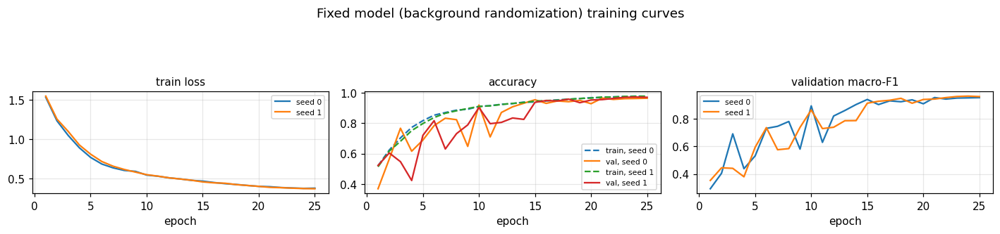

In [23]:
fixed_models, fixed_hist = {}, {}
for seed in CFG.seeds:
    fixed_models[seed], fixed_hist[seed] = train_model("fixed", seed, background_swap=True)
fixed = fixed_models[CFG.seeds[0]]
mem_report("fixed models trained")
plot_history(fixed_hist, "Fixed model (background randomization) training curves")

## 6. Before / after

### 6.1 Quantitative comparison (mean ± std over seeds)

In [24]:
def full_eval(model, keep_cams: bool = False, cams=None) -> dict:
    """All before/after metrics for one model. Heatmaps are kept only when needed for plots (RAM)."""
    if cams is None:
        cams, logits = compute_cams(model, X_TE)
    else:
        logits = predict_logits(model, X_TE)
    pred = logits.argmax(1).numpy()
    energy = cam_energy(cams, M_TE)
    st = stress_suite(model, STRESS_TE, y_te, PARTNER_TE)
    return {"pred": pred, "cams": cams if keep_cams else None, "energy": energy, "stress": st,
            "macro_f1": f1_score(y_te, pred, average="macro")}


s0 = CFG.seeds[0]
EVAL = {("baseline", s): full_eval(m, keep_cams=(s == s0), cams=CAMS_B if s == s0 else None)   # reuse section 4's maps
        for s, m in baseline_models.items()}
EVAL.update({("fixed", s): full_eval(m, keep_cams=(s == s0)) for s, m in fixed_models.items()})
mem_report("before/after evaluation done")

rows = []
for (name, seed), r in EVAL.items():
    st, en = r["stress"], r["energy"]
    rows.append({"model": name, "seed": seed,
                 "clean accuracy ↑": st["clean"], "clean macro-F1 ↑": r["macro_f1"],
                 "black background ↑": st["black background"],
                 "cross-class background ↑ (held-out)": st["cross-class background"],
                 "held-out textures ↑ (held-out)": st["held-out textures"],
                 "follows background class ↓": st["follows background class"],
                 "background only ↓ (chance 10%)": st["background only"],
                 "Grad-CAM energy on leaf ↑": en.leaf_ratio.mean(),
                 "Grad-CAM energy on background ↓": en.energy_background.mean(),
                 "Grad-CAM peak on leaf ↑": en.peak_on_leaf.mean()})
RESULTS = pd.DataFrame(rows)
metric_cols = [c for c in RESULTS.columns if c not in ("model", "seed")]
agg = RESULTS.drop(columns="seed").groupby("model").agg(["mean", "std"]).T.unstack(level=1).reindex(metric_cols)
COMPARISON = pd.DataFrame({m: [f"{agg.loc[k, (m, 'mean')]:.1%} ± {np.nan_to_num(agg.loc[k, (m, 'std')]):.1%}" for k in agg.index]
                           for m in ["baseline", "fixed"]}, index=agg.index)
COMPARISON["Δ (fixed − baseline)"] = [f"{agg.loc[k, ('fixed', 'mean')] - agg.loc[k, ('baseline', 'mean')]:+.1%}" for k in agg.index]
display(COMPARISON)
RESULTS.to_csv(CFG.artifacts / "results_per_seed.csv", index=False)

[memory] before/after evaluation done: process 6.0 GB | system 6.8 / 13.6 GB


,baseline,fixed,Δ (fixed − baseline)
clean accuracy ↑,99.0% ± 0.1%,96.9% ± 1.0%,-2.1%
clean macro-F1 ↑,98.9% ± 0.2%,96.2% ± 1.1%,-2.8%
black background ↑,19.1% ± 2.7%,90.9% ± 2.5%,+71.8%
cross-class background ↑ (held-out),66.5% ± 0.8%,94.5% ± 1.0%,+27.9%
held-out textures ↑ (held-out),26.8% ± 0.0%,72.0% ± 0.6%,+45.2%
follows background class ↓,11.7% ± 0.1%,0.9% ± 0.2%,-10.8%
background only ↓ (chance 10%),42.2% ± 3.1%,11.4% ± 0.6%,-30.9%
Grad-CAM energy on leaf ↑,54.1% ± 0.0%,64.8% ± 0.5%,+10.7%
Grad-CAM energy on background ↓,34.2% ± 0.1%,24.2% ± 0.4%,-10.0%
Grad-CAM peak on leaf ↑,87.4% ± 0.7%,96.8% ± 0.4%,+9.4%


**Is the difference real?** McNemar's test compares the two models *on the same images*: it only looks at images
where exactly one model is right. A small p-value means the difference is unlikely to be luck.

In [25]:
def mcnemar(pred_a, pred_b, y) -> tuple[int, int, float]:
    a_ok, b_ok = pred_a == y, pred_b == y
    only_a, only_b = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p


s0 = CFG.seeds[0]
for cond in ["clean", "cross-class background", "held-out textures"]:
    pa = predict_logits(baseline_models[s0], STRESS_TE[cond]).argmax(1).numpy()
    pb = predict_logits(fixed_models[s0], STRESS_TE[cond]).argmax(1).numpy()
    oa, ob, p = mcnemar(pa, pb, y_te)
    print(f"{cond:>24s}: only baseline right {oa:4d} | only fixed right {ob:4d} | McNemar p = {p:.2g}")

                   clean: only baseline right   84 | only fixed right   13 | McNemar p = 6.9e-14
  cross-class background: only baseline right   39 | only fixed right  728 | McNemar p = 1.6e-165
       held-out textures: only baseline right  136 | only fixed right 1294 | McNemar p = 3.6e-237


### 6.2 Per-class view

,F1 clean — baseline,F1 clean — fixed,acc. cross-class bg — baseline,acc. cross-class bg — fixed
Bacterial spot,0.990,0.975,0.701,0.938
Early blight,0.997,0.899,0.507,0.799
Late blight,0.990,0.968,0.809,0.962
Leaf mold,0.996,0.982,0.609,0.942
Septoria,0.998,0.953,0.444,0.988
Spider mites,0.982,0.955,0.732,0.862
Target spot,0.964,0.897,0.350,0.770
Yellow leaf curl,0.997,0.995,0.918,0.984
Mosaic virus,0.990,0.990,0.176,0.980
Healthy,0.977,0.924,0.368,0.996


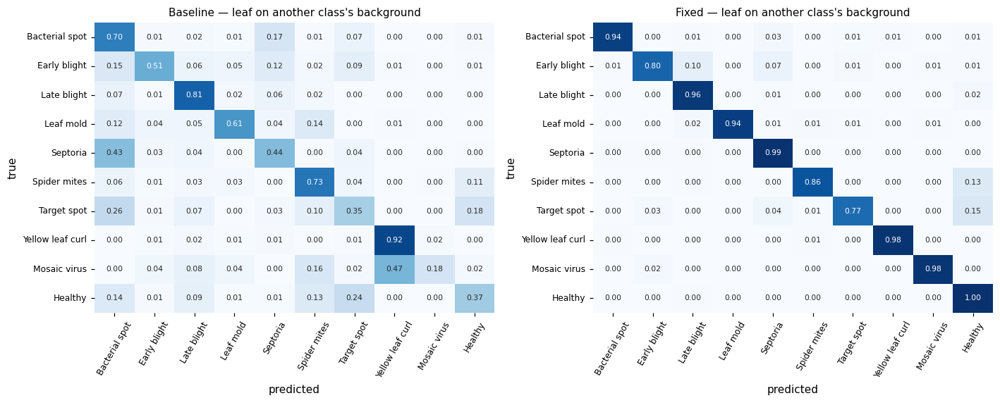

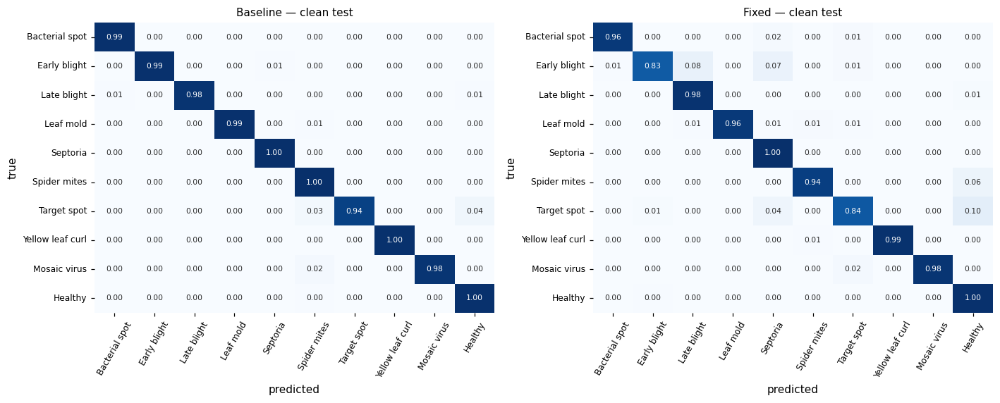

In [26]:
FB, FF = EVAL[("baseline", s0)], EVAL[("fixed", s0)]
f1_b = f1_score(y_te, FB["pred"], average=None, labels=range(N_CLASSES))
f1_f = f1_score(y_te, FF["pred"], average=None, labels=range(N_CLASSES))
pred_cross_f = FF["stress"]["_pred_cross"]
acc_cross = lambda pred: [accuracy_score(y_te[y_te == c], pred[y_te == c]) for c in range(N_CLASSES)]
per_class = pd.DataFrame({"F1 clean — baseline": f1_b, "F1 clean — fixed": f1_f,
                          "acc. cross-class bg — baseline": acc_cross(FB["stress"]["_pred_cross"]),
                          "acc. cross-class bg — fixed": acc_cross(pred_cross_f)}, index=SHORT)
display(per_class.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.5, vmax=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.3))
plot_confusion(y_te, FB["stress"]["_pred_cross"], "Baseline — leaf on another class's background", ax=axes[0])
plot_confusion(y_te, pred_cross_f, "Fixed — leaf on another class's background", ax=axes[1])
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3))
plot_confusion(y_te, FB["pred"], "Baseline — clean test", ax=axes[0])
plot_confusion(y_te, FF["pred"], "Fixed — clean test", ax=axes[1])
plt.tight_layout(); plt.show()

### 6.3 Grad-CAM before vs after — same images
Columns: the clean image with the baseline's and the fixed model's heatmaps, then the same leaf on another class's
background with both heatmaps. Rows are the images with the **largest baseline background energy** (the cases the fix
targets), plus random ones so the comparison is not cherry-picked.

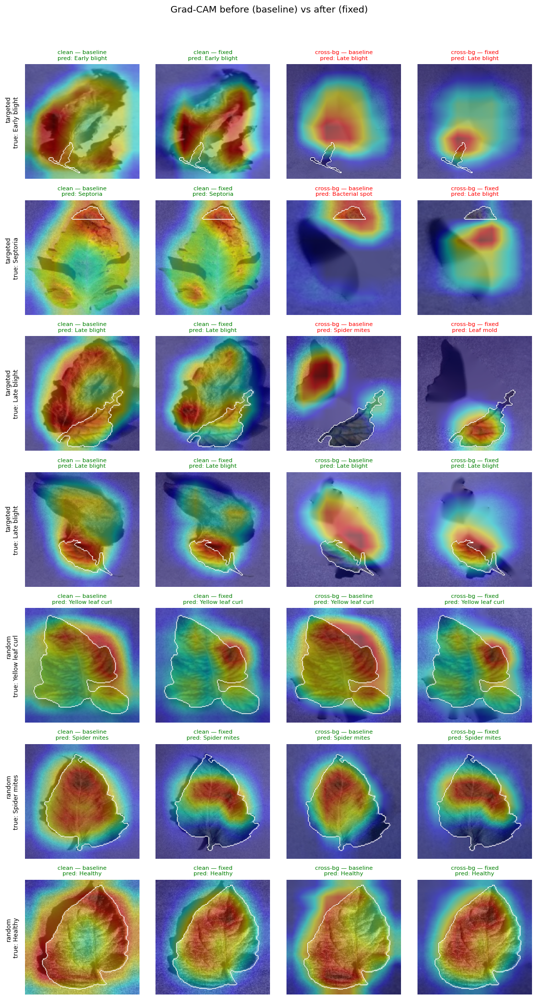

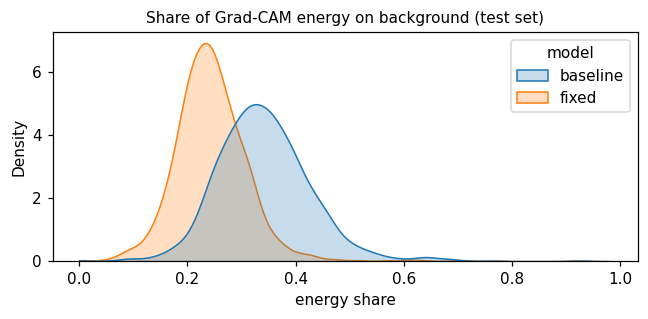

In [27]:
CAMS_F_CROSS, LOGITS_F_CROSS = compute_cams(fixed, STRESS_TE["cross-class background"])
targeted = EN_B.energy_background.sort_values(ascending=False).index[:4].tolist()
randoms = rng.choice(len(y_te), 3, replace=False).tolist()
Xc = STRESS_TE["cross-class background"]
cols = [("clean — baseline", X_TE, FB["cams"], FB["pred"]), ("clean — fixed", X_TE, FF["cams"], FF["pred"]),
        ("cross-bg — baseline", Xc, CAMS_B_CROSS, pred_cross_b), ("cross-bg — fixed", Xc, CAMS_F_CROSS, LOGITS_F_CROSS.argmax(1).numpy())]
rows_i = targeted + randoms
fig, axes = plt.subplots(len(rows_i), 4, figsize=(10, 2.6 * len(rows_i)))
for r, i in enumerate(rows_i):
    for c, (title, Xs, cams, pred) in enumerate(cols):
        axes[r, c].imshow(overlay(u8(Xs[i]), cams[i].float().numpy(), mask=M_TE[i, 0].numpy())); axes[r, c].axis("off")
        axes[r, c].set_title(f"{title}\npred: {SHORT[pred[i]]}", fontsize=7.5, color="green" if pred[i] == y_te[i] else "red")
    axes[r, 0].text(-8, 80, f"{'targeted' if i in targeted else 'random'}\ntrue: {SHORT[y_te[i]]}", rotation=90, va="center", ha="right", fontsize=8)
finish_figure("Grad-CAM before (baseline) vs after (fixed)")

energy_long = pd.concat([FB["energy"].assign(model="baseline"), FF["energy"].assign(model="fixed")])
plt.figure(figsize=(6, 3))
sns.kdeplot(data=energy_long, x="energy_background", hue="model", fill=True, common_norm=False, clip=(0, 1))
plt.title("Share of Grad-CAM energy on background (test set)"); plt.xlabel("energy share"); plt.tight_layout(); plt.show()
display(pd.concat({"baseline": summarize_energy(FB["energy"]), "fixed": summarize_energy(FF["energy"])}, axis=1).style.format(precision=3))

## 7. Inference tool: prediction + heatmap + trust level

A trustworthy tool must say **when not to trust it**. Our trust level combines three independent signals:

1. **Calibrated confidence.** Raw softmax probabilities of neural nets are usually over-confident. We fit a single
   *temperature* $T$ (Guo et al., 2017): $p = \mathrm{softmax}(z / T)$, chosen to minimise validation negative
   log-likelihood. It does not change the predicted class, only makes "90 % sure" mean ≈ 90 % correct.
2. **Explanation check (Grad-CAM).** The share of Grad-CAM energy that lies on the leaf. If the evidence is mostly
   outside the leaf, the prediction is based on the wrong thing — exactly the failure we diagnosed. New photos have
   no ground-truth mask, so we estimate the leaf with a lightweight colour segmenter (validated below).
3. **Input check.** Is there a plausible leaf at all (leaf area, leaf-coloured pixels)? Catches non-leaf images.

The thresholds are **chosen on validation data** (clean + cross-class backgrounds), and evaluated on test data,
including held-out textures that were not used to choose them.

Leaf-segmenter IoU vs ground truth — clean: median 0.910 (mean 0.834); cross-class background: median 0.911


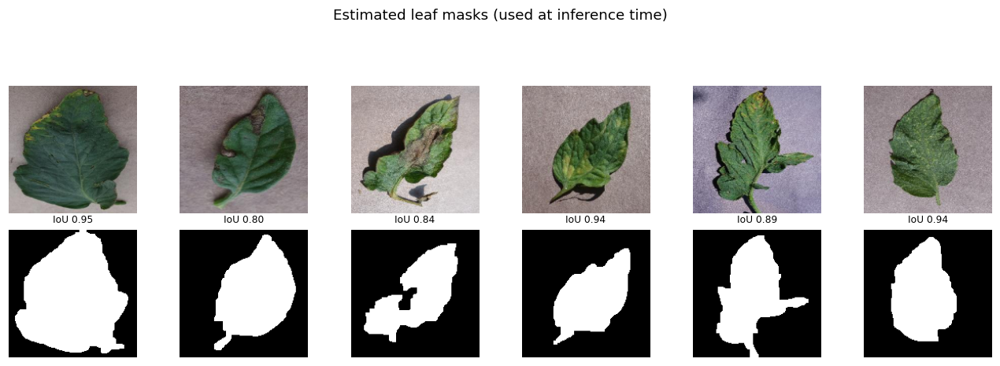

In [28]:
final_model = fixed           # the model we ship


def estimate_leaf_mask(rgb: np.ndarray) -> np.ndarray:
    """Leaf mask without ground truth: Otsu threshold on HSV saturation + morphology + largest blob."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    sat = cv2.GaussianBlur(hsv[..., 1], (5, 5), 0)
    t, _ = cv2.threshold(sat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = ((sat >= t) & (hsv[..., 2] > 30)).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    return largest_component_filled(mask)


def leaf_colour_fraction(rgb: np.ndarray) -> float:
    """Share of the whole image with a saturated plant-like hue (yellow → green; OpenCV hue 18–90).
    Measured on the whole image so it does not depend on the segmenter; browns/oranges (hue < 18) are excluded."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV).reshape(-1, 3)
    return float(((hsv[:, 0] >= 18) & (hsv[:, 0] <= 90) & (hsv[:, 1] >= 40)).mean())


def iou(a, b):
    return (a & b).sum() / max((a | b).sum(), 1)


est_clean = [estimate_leaf_mask(u8(X_TE[i])) for i in range(len(X_TE))]
est_cross = [estimate_leaf_mask(u8(STRESS_TE["cross-class background"][i])) for i in range(len(X_TE))]
iou_clean = np.array([iou(e.astype(bool), M_TE[i, 0].numpy().astype(bool)) for i, e in enumerate(est_clean)])
iou_cross = np.array([iou(e.astype(bool), M_TE[i, 0].numpy().astype(bool)) for i, e in enumerate(est_cross)])
print(f"Leaf-segmenter IoU vs ground truth — clean: median {np.median(iou_clean):.3f} (mean {iou_clean.mean():.3f}); "
      f"cross-class background: median {np.median(iou_cross):.3f}")
fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for c, i in enumerate(one_per_class[:6]):
    axes[0, c].imshow(u8(X_TE[i])); axes[1, c].imshow(est_clean[i], cmap="gray"); axes[1, c].set_title(f"IoU {iou_clean[i]:.2f}", fontsize=8)
for a in axes.flat: a.axis("off")
finish_figure("Estimated leaf masks (used at inference time)")

fitted temperature T = 0.691


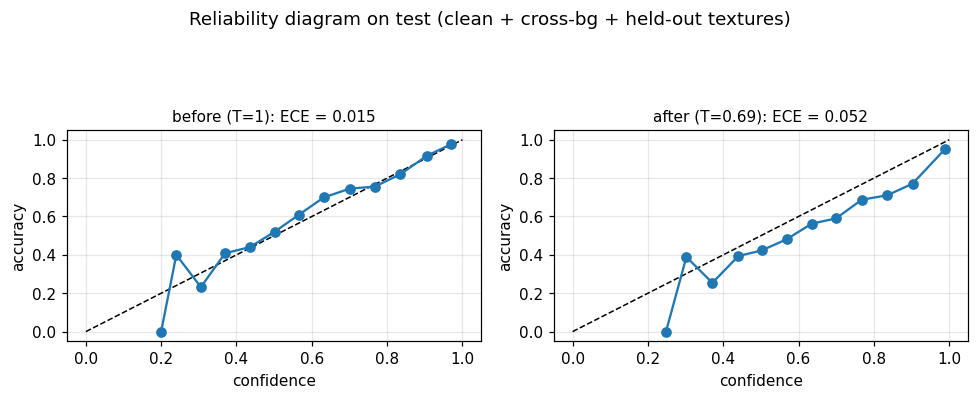

In [29]:
def fit_temperature(logits: torch.Tensor, y: torch.Tensor) -> float:
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(logits / log_t.exp(), y); loss.backward(); return loss
    opt.step(closure)
    return float(log_t.exp().clamp(0.05, 20.0))      # guard against a degenerate fit


def expected_calibration_error(probs: np.ndarray, y: np.ndarray, n_bins: int = 15):
    conf, pred = probs.max(1), probs.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1); ece, curve = 0.0, []
    for lo, hi in zip(bins[:-1], bins[1:]):
        sel = (conf > lo) & (conf <= hi)
        if sel.any():
            acc, c = (pred[sel] == y[sel]).mean(), conf[sel].mean()
            ece += sel.mean() * abs(acc - c); curve.append((c, acc, sel.sum()))
    return ece, np.array(curve)


# Calibration / threshold-selection set: validation images, clean + leaf on another class's background.
y_va = Y_VA.numpy()
X_VA_CROSS, _ = cross_class_set(X_VA, M_VA, y_va, seed=1)
CAL_SETS = [X_VA, X_VA_CROSS]                    # kept as two tensors (no concatenated copy)
Y_CAL = np.concatenate([y_va, y_va])
logits_cal = torch.cat([predict_logits(final_model, X) for X in CAL_SETS])
TEMPERATURE = fit_temperature(logits_cal, torch.from_numpy(Y_CAL))
print(f"fitted temperature T = {TEMPERATURE:.3f}")

test_logits = torch.cat([predict_logits(final_model, STRESS_TE[c]) for c in ["clean", "cross-class background", "held-out textures"]])
y_rep = np.tile(y_te, 3)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, T) in zip(axes, [("before (T=1)", 1.0), (f"after (T={TEMPERATURE:.2f})", TEMPERATURE)]):
    ece, curve = expected_calibration_error(F.softmax(test_logits / T, 1).numpy(), y_rep)
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(curve[:, 0], curve[:, 1], "o-")
    ax.set_title(f"{name}: ECE = {ece:.3f}"); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.grid(alpha=0.3)
finish_figure("Reliability diagram on test (clean + cross-bg + held-out textures)")

In [30]:
def trust_features(model, X: torch.Tensor, chunk: int = 256, return_cams: bool = False):
    """Everything the trust rule needs, for uint8 images: calibrated probs, CAM-on-leaf, input checks.
    Works through the images in chunks so heatmaps for thousands of images are never held in RAM at once."""
    rows, all_probs, kept_cams = [], [], []
    for start in range(0, len(X), chunk):
        xs = X[start:start + chunk]
        cams, logits = compute_cams(model, xs)
        probs = F.softmax(logits / TEMPERATURE, dim=1).numpy()
        for i in range(len(xs)):
            rgb = np.ascontiguousarray(u8(xs[i])); m = estimate_leaf_mask(rgb); c = cams[i].float().numpy()
            rows.append({"pred": int(probs[i].argmax()), "confidence": float(probs[i].max()),
                         "cam_on_leaf": float((c * m).sum() / (c.sum() + 1e-8)),
                         "leaf_area": float(m.mean()), "leaf_colour": leaf_colour_fraction(rgb)})
        all_probs.append(probs)
        if return_cams:
            kept_cams.append(cams)
    return pd.DataFrame(rows), (torch.cat(kept_cams) if return_cams else None), np.concatenate(all_probs)


def pick_threshold(score: np.ndarray, correct: np.ndarray, target_acc: float) -> float:
    """Lowest score threshold such that predictions above it are at least `target_acc` accurate (on calibration data)."""
    order = np.argsort(-score)
    cum_acc = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
    ok = np.where(cum_acc >= target_acc)[0]
    return float(score[order][ok.max()]) if len(ok) else 1.01


TF_CAL = pd.concat([trust_features(final_model, X)[0] for X in CAL_SETS], ignore_index=True)
mem_report("trust calibration features computed")
cal_correct = (TF_CAL.pred.values == Y_CAL)
TH = {
    "min_leaf_area": 0.05,                                              # less than 5% of the image is leaf → no leaf
    "min_leaf_colour": float(np.quantile(TF_CAL.leaf_colour, 0.01)),    # 99% of real leaf photos have more leaf-coloured pixels
    "min_cam_on_leaf": 0.5,                                             # the majority of the evidence must be on the leaf
}
on_leaf = TF_CAL.cam_on_leaf.values >= TH["min_cam_on_leaf"]
TH["high_conf"] = pick_threshold(np.where(on_leaf, TF_CAL.confidence.values, 0), cal_correct, 0.99)
TH["medium_conf"] = pick_threshold(TF_CAL.confidence.values, cal_correct, 0.90)
print(json.dumps({k: round(v, 4) for k, v in TH.items()}, indent=2))

bins = pd.cut(TF_CAL.cam_on_leaf, [0, .3, .5, .7, .9, 1.0], include_lowest=True)
display(pd.DataFrame({"images": TF_CAL.groupby(bins, observed=False).size(),
                      "accuracy": pd.Series(cal_correct).groupby(bins, observed=False).mean()})
        .style.format({"accuracy": "{:.1%}"}).set_caption("Validation: accuracy vs share of Grad-CAM energy on the (estimated) leaf"))

[memory] trust calibration features computed: process 6.6 GB | system 7.5 / 13.6 GB
{
  "min_leaf_area": 0.05,
  "min_leaf_colour": 0.137,
  "min_cam_on_leaf": 0.5,
  "high_conf": 0.8844,
  "medium_conf": 0.2042
}


,images,accuracy
cam_on_leaf,,
"(-0.001, 0.3]",199,80.9%
"(0.3, 0.5]",435,92.4%
"(0.5, 0.7]",3457,96.8%
"(0.7, 0.9]",1080,94.5%
"(0.9, 1.0]",25,92.0%


In [31]:
def assess_trust(confidence: float, cam_on_leaf: float, leaf_area: float, leaf_colour: float) -> tuple[str, list[str]]:
    """Rule-based trust level. Returns (level, human-readable reasons)."""
    reasons = []
    if leaf_area < TH["min_leaf_area"]:
        reasons.append(f"no clear leaf found (leaf covers {leaf_area:.0%} of the image)")
    if leaf_colour < TH["min_leaf_colour"]:
        reasons.append(f"colours are not typical of a tomato leaf (only {leaf_colour:.0%} of pixels are leaf-green/yellow)")
    if reasons:
        return "LOW", reasons
    if cam_on_leaf < TH["min_cam_on_leaf"]:
        reasons.append(f"only {cam_on_leaf:.0%} of the model's evidence is on the leaf")
    if confidence >= TH["high_conf"] and cam_on_leaf >= TH["min_cam_on_leaf"]:
        return "HIGH", [f"calibrated confidence {confidence:.1%}", f"{cam_on_leaf:.0%} of evidence on the leaf"]
    if confidence >= TH["medium_conf"]:
        return "MEDIUM", reasons + [f"calibrated confidence {confidence:.1%}"]
    return "LOW", reasons + [f"low calibrated confidence {confidence:.1%}"]


def trust_report(tf: pd.DataFrame, y: np.ndarray) -> pd.DataFrame:
    levels = [assess_trust(r.confidence, r.cam_on_leaf, r.leaf_area, r.leaf_colour)[0] for r in tf.itertuples()]
    df = pd.DataFrame({"level": levels, "correct": tf.pred.values == y})
    out = df.groupby("level").agg(share=("correct", "size"), accuracy=("correct", "mean"))
    out["share"] /= len(df)
    return out.reindex(["HIGH", "MEDIUM", "LOW"])


trust_eval = {cond: trust_report(trust_features(final_model, STRESS_TE[cond])[0], y_te)
              for cond in ["clean", "cross-class background", "held-out textures"]}
display(pd.concat(trust_eval, axis=1).style.format("{:.1%}", na_rep="–").set_caption(
    "Test set: share of images at each trust level and the accuracy within that level"))

### 7.1 The tool
`predict()` accepts a file path, a PIL image or a numpy array of **any size / colour mode**, and returns a
`Prediction` with the class, calibrated probabilities, the Grad-CAM heatmap (at the original resolution), the
overlay, and the trust level with its reasons. `Prediction.show()` draws it.

In [32]:
from PIL import Image


@dataclass
class Prediction:
    label: str
    confidence: float
    top3: list
    trust: str
    reasons: list
    heatmap: np.ndarray = field(repr=False)          # HxW in [0,1], original image size
    overlay: np.ndarray = field(repr=False)          # HxWx3 uint8
    image: np.ndarray = field(repr=False)

    def show(self):
        colour = {"HIGH": "green", "MEDIUM": "orange", "LOW": "red"}[self.trust]
        fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1, 0.9]})
        axes[0].imshow(self.image); axes[0].set_title("input"); axes[1].imshow(self.overlay); axes[1].set_title("Grad-CAM")
        for a in axes[:2]: a.axis("off")
        names, ps = zip(*self.top3)
        axes[2].barh(names[::-1], ps[::-1], color="#4C72B0"); axes[2].set_xlim(0, 1); axes[2].set_title("top-3 (calibrated)")
        fig.suptitle(f"{self.label}  —  trust: {self.trust}\n" + "; ".join(self.reasons), color=colour, fontsize=10)
        plt.tight_layout(); plt.show()


def load_rgb(image) -> np.ndarray:
    if isinstance(image, (str, Path)):
        image = Image.open(image)
    if isinstance(image, Image.Image):
        image = np.array(image.convert("RGB"))
    image = np.asarray(image)
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    if image.shape[-1] == 4:
        image = image[..., :3]
    if image.dtype != np.uint8:
        image = np.uint8(np.clip(image * (255 if image.max() <= 1 else 1), 0, 255))
    return image


def predict(image, model: nn.Module = None) -> Prediction:
    """Prediction + Grad-CAM heatmap + trust level for one image (path / PIL / numpy, any size)."""
    model = model or final_model
    rgb = load_rgb(image)
    small = cv2.resize(rgb, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_AREA)
    x = torch.from_numpy(small).permute(2, 0, 1)[None].contiguous()
    tf, cams, probs = trust_features(model, x, return_cams=True)
    r = tf.iloc[0]
    level, reasons = assess_trust(r.confidence, r.cam_on_leaf, r.leaf_area, r.leaf_colour)
    heat = cv2.resize(cams[0].float().numpy(), (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_LINEAR)
    top = probs[0].argsort()[::-1][:3]
    return Prediction(label=SHORT[top[0]], confidence=float(probs[0, top[0]]),
                      top3=[(SHORT[k], float(probs[0, k])) for k in top], trust=level, reasons=reasons,
                      heatmap=heat, overlay=overlay(rgb, heat), image=rgb)


# Save everything needed to use the tool outside this notebook.
torch.save({"state_dict": final_model.state_dict(), "classes": SHORT, "mean": CH_MEAN, "std": CH_STD,
            "img_size": CFG.img_size, "temperature": TEMPERATURE, "thresholds": TH}, CFG.artifacts / "final_model.pt")
print("saved", CFG.artifacts / "final_model.pt")

saved /content/artifacts/final_model.pt


### 7.2 Demo
1. A normal test photo (original file, full 256 px resolution — the tool resizes it itself).
2. A test leaf on a background from another class (the failure case we fixed).
3. A leaf on a real-world texture it never saw.
4. A picture that is **not a leaf** at all — the tool should refuse to trust itself.

test photo (file on disk): Late blight (50.4%), trust MEDIUM — ['calibrated confidence 50.4%']


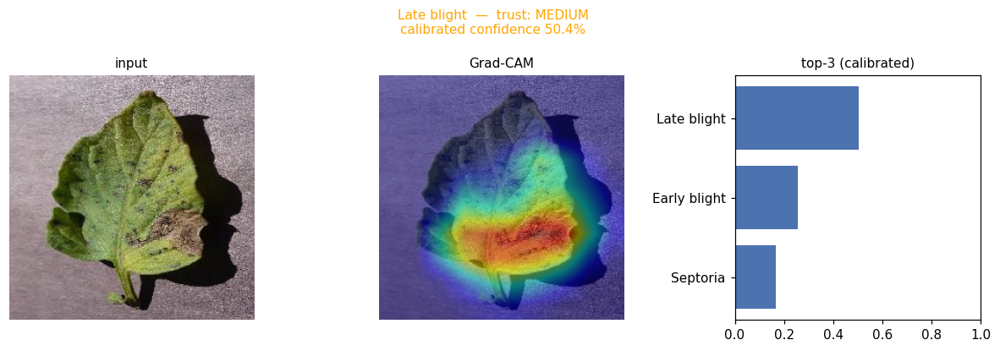

leaf on another class's background: Late blight (63.3%), trust MEDIUM — ['calibrated confidence 63.3%']


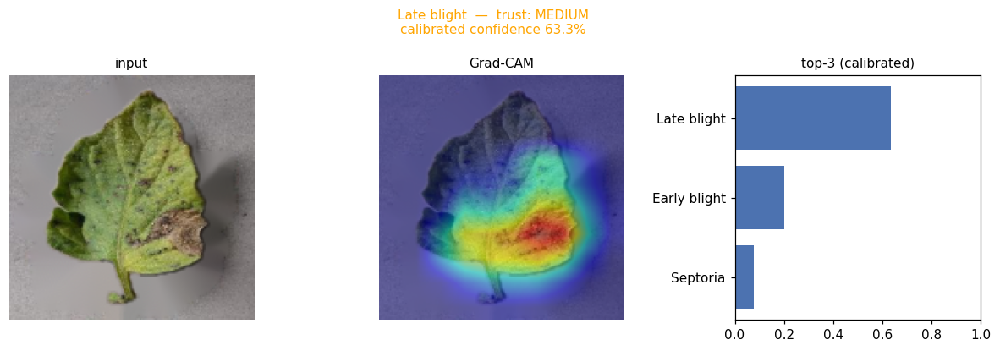

leaf on held-out texture: Leaf mold (99.9%), trust MEDIUM — ["only 40% of the model's evidence is on the leaf", 'calibrated confidence 99.9%']


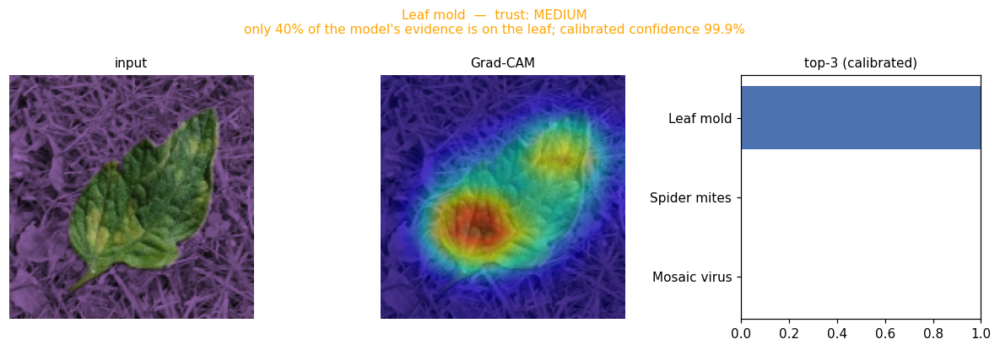

not a leaf (coffee cup): Late blight (72.8%), trust LOW — ['colours are not typical of a tomato leaf (only 0% of pixels are leaf-green/yellow)']


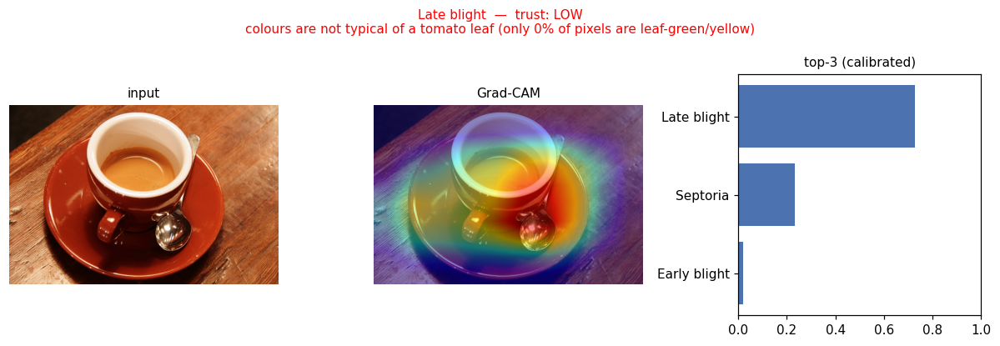

In [33]:
from skimage import data as skdata

demo_i = int(np.where(y_te == 1)[0][0]) if (y_te == 1).any() else 0
demos = {
    "test photo (file on disk)": meta.color_path.values[IDX_TE[demo_i]],
    "leaf on another class's background": u8(STRESS_TE["cross-class background"][demo_i]),
    "leaf on held-out texture": u8(STRESS_TE["held-out textures"][one_per_class[3]]),
    "not a leaf (coffee cup)": skdata.coffee(),
}
for name, img in demos.items():
    p = predict(img)
    print(f"{name}: {p.label} ({p.confidence:.1%}), trust {p.trust} — {p.reasons}")
    p.show()

**Try your own photo.** In Colab, set `UPLOAD = True` and run the cell (it is off by default so *Run all* does not
stop). Optionally, `LAUNCH_GRADIO = True` starts a small web UI for a live demo.

In [34]:
UPLOAD, LAUNCH_GRADIO = False, False

if UPLOAD and IN_COLAB:
    from google.colab import files
    for fname in files.upload():
        predict(fname).show()

if LAUNCH_GRADIO:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

    def gradio_fn(img):
        p = predict(img)
        return {k: v for k, v in p.top3}, p.overlay, f"Trust: {p.trust}\n" + "\n".join(p.reasons)

    gr.Interface(gradio_fn, gr.Image(type="numpy"), [gr.Label(num_top_classes=3), gr.Image(), gr.Textbox()],
                 title="Tomato leaf disease — prediction, Grad-CAM, trust").launch(share=True)

## 8. Technical report

The table below is generated from this run; the written report follows.

In [35]:
summary = pd.concat([diagnosis_summary("baseline", FB["energy"], FB["stress"]),
                     diagnosis_summary("fixed", FF["energy"], FF["stress"])], axis=1)
summary["Δ"] = summary.fixed - summary.baseline
display(summary.style.format("{:+.1%}", subset=["Δ"]).format("{:.1%}", subset=["baseline", "fixed"])
        .set_caption(f"Key numbers (seed {s0}); see Section 6.1 for mean ± std over seeds"))

,baseline,fixed,Δ
clean test accuracy,99.0%,96.2%,-2.7%
Grad-CAM energy on background,34.1%,24.5%,-9.7%
Grad-CAM energy on leaf boundary,24.2%,24.0%,-0.2%
Grad-CAM peak off the leaf,12.1%,2.9%,-9.2%
"accuracy, background only (chance 10%)",40.0%,11.8%,-28.3%
"accuracy, leaf on another class's background",67.1%,93.7%,+26.6%
→ prediction follows the background's class,11.8%,1.0%,-10.7%
"accuracy, held-out textures",26.8%,71.6%,+44.8%


### Report: diagnosing and fixing a background shortcut in a tomato-disease CNN

All numbers come from this run. "±" is the standard deviation over the two training seeds.

**1. Problem and baseline.** I trained a 2.4 M-parameter VGG-style CNN from scratch on the 10 tomato classes of PlantVillage (18,159 images at 160 px). The split is by *physical leaf*, because 291 leaves were photographed more than once; no leaf appears in both train and test. The baseline reaches **99.0% ± 0.1% test accuracy and 98.9% ± 0.2% macro-F1**. Its weakest classes are Target spot (F1 0.964), Healthy (0.977) and Spider mites (0.982); the most common mistake is Target spot predicted as Healthy.

**2. Diagnosis.** The data audit showed that every one of the 20 capture sessions contains a single disease, so the session code alone labels 100% of the images. A Random Forest that sees *only background colours* reaches 86.9% test accuracy (chance is 10%). The background is therefore a label leak.

Grad-CAM was implemented from scratch and passed the model-randomisation sanity check (rank correlation with a random-weights model: 0.09). On the baseline it puts 34.1% of its energy on the background, and its peak lies off the leaf on 12.1% of test images. That is suggestive, not conclusive: the background covers 52% of the image, so the heatmap is still concentrated on the leaf. The interventions are what prove the shortcut:

| Intervention on the test images | Baseline accuracy |
|---|---|
| None (clean) | 99.0% |
| Leaf removed, background only | 40.0% (chance 10%) |
| Leaf on the dataset's own black background | 21.0% |
| Leaf on a background from another class | 67.1% |
| Leaf on held-out real textures | 26.8% |

Of the 830 test images that were right on clean but wrong after a cross-class background swap, 299 (36%) switched to the class the background came from. The failure pattern is: **the baseline uses the photo's background, which identifies the capture session and so the class, as evidence for the disease.** It holds for every class (worst: Mosaic virus 17.6%, Target spot 35.0%, Healthy 36.8% accuracy on a foreign background) and for both seeds.

**3. Fix.** The cause is a spurious correlation in the data, so the fix removes it at the source. During training, with probability 0.8, the leaf is cut out with its mask and pasted onto a random synthetic background (solid colour, gradient, blobs, grey texture or noise). The background then carries no information about the label. Architecture, split, hyper-parameters, epochs, seeds and all other augmentation are identical to the baseline. The evaluation uses backgrounds the fixed model never saw: real backgrounds from other classes and real texture photographs.

**4. Results.**

| Metric | Baseline | Fixed | Change |
|---|---|---|---|
| Clean accuracy | 99.0% ± 0.1% | 96.9% ± 1.0% | −2.1 |
| Clean macro-F1 | 98.9% ± 0.2% | 96.2% ± 1.1% | −2.8 |
| Black background | 19.1% ± 2.7% | 90.9% ± 2.5% | +71.8 |
| Another class's background (held-out) | 66.5% ± 0.8% | 94.5% ± 1.0% | +27.9 |
| Held-out textures | 26.8% ± 0.0% | 72.0% ± 0.6% | +45.2 |
| Background only (lower is better) | 42.2% ± 3.1% | 11.4% ± 0.6% | −30.9 |
| Prediction follows the background's class | 11.7% ± 0.1% | 0.9% ± 0.2% | −10.8 |
| Grad-CAM energy on the leaf | 54.1% | 64.8% ± 0.5% | +10.7 |
| Grad-CAM peak on the leaf | 87.4% ± 0.7% | 96.8% ± 0.4% | +9.4 |

The fix did what it was designed to do. With the leaf removed the fixed model is at chance, and it almost never follows a foreign background. On the two held-out background tests the gains are far larger than the seed-to-seed spread and McNemar's test gives p < 10⁻¹⁰⁰ for both. The before/after Grad-CAM panel shows the same change qualitatively: the heatmap stays on the leaf when the background changes.

The fix has a real cost. Clean accuracy fell by 2.1 points, and this is not noise: on the clean test set 84 images are right only for the baseline and 13 only for the fixed model (McNemar p = 7 × 10⁻¹⁴). Early blight (F1 0.997 → 0.899) and Target spot (0.964 → 0.897) lost the most. Two things explain it. First, the clean test set shares the shortcut with the training set, so part of the baseline's 99% was earned from the background. Second, the fixed model has a harder training task and was still improving when training ended at epoch 25 (validation F1 was still rising), so it is probably under-trained. The fix is also incomplete: 72% on held-out textures is far better than 27%, but well short of the clean score.

**5. Inference tool.** `predict()` takes a path, PIL image or array of any size and returns the class, calibrated top-3 probabilities, the Grad-CAM heatmap and overlay, and a trust level with its reasons. Trust combines calibrated confidence (temperature scaling, T = 0.69), the share of Grad-CAM evidence on the estimated leaf, and leaf-presence checks. HIGH works as intended on images like the training data: 80.3% of clean test images are rated HIGH and 98.9% of those are correct (77.5% and 98.6% on foreign backgrounds). The non-leaf demo image is correctly rated LOW.

The other two levels do not work well, and I report that plainly:

- **MEDIUM is too permissive.** Its confidence cutoff came out at 0.20, because overall validation accuracy already exceeded the 90% target. So almost no prediction is rated LOW for low confidence. On clean test images MEDIUM is 84.5% accurate while LOW is 93.8% accurate, which is the wrong order. LOW currently means only "the input does not look like a leaf".
- **Trust does not transfer fully to new backgrounds.** On held-out textures HIGH is 88.0% accurate, not 99%.
- **Temperature scaling did not help here.** On the mixed test set (clean + foreign backgrounds + textures) the calibration error rose from 0.015 to 0.052. T was fitted on validation images that are easier than that mix, so it made the model more confident than it should be on the harder images.
- **The first demo image shows the weakness.** An Early blight leaf is predicted as Late blight at 50% confidence and rated MEDIUM; it should be LOW.

**6. Limitations.**
- All images are lab photos of single detached leaves. Field photos are a much larger shift than any test here.
- About 0.5% of the dataset's background-removed images keep only a fragment of the leaf (mostly dark, dead leaves). Their masks are wrong, and they dominate the "most background-focused image of each class" figure in section 4.2, so that figure overstates the problem for those images. The aggregate numbers are barely affected.
- The colour-based leaf detector used at inference has a median IoU of 0.91 with the true masks but a mean of 0.83; in a separate check it fails (IoU below 0.5) on about 7% of images, which weakens the "evidence on the leaf" signal.
- Inpainted background-only images can keep the leaf's shadow and outline, so the 40% background-only score may include some shape information.
- Grad-CAM maps are coarse (10 × 10), and two seeds give only a rough idea of variance.

**7. What I would do next.**
1. Repair the trust level: set the MEDIUM cutoff from accuracy *below* the threshold, and fit the temperature on data that includes shifted backgrounds.
2. Replace the leaf detector (an Otsu threshold on the Lab b−a channel cut failures from 7% to 0.4% in a quick test) and exclude the broken masks from training and evaluation.
3. Train both models longer with an equal budget to see how much of the 2.1-point clean gap closes.
4. Test on field images (for example PlantDoc) and fine-tune on a small number of them.
5. Try a pretrained backbone under the same diagnosis protocol, and an attention-supervision loss as a second, complementary fix.